# Primary AlphaMissense — Effective alignment depth

This notebook records the original investigation from source acquisition and processing to the diagnostic or curve used for the agent's determination. Original disposition: **rejected**. Retained and discarded candidates are both included. This is a historical computation record, not a new protocol-compliance assessment.

The original primary AlphaMissense files came from the separately archived AlphaMissense run; no matching run directory was found in the bounded exxact05 search. Exact input identities, original code and replay boundaries are shown below.

## Data acquisition and source identity

**Portable checkout.** Install `../requirements.txt` using Python3.11. The first code cell verifies and restores only axis3 inputs. Git payloads are offline; axis1 additionally downloads the exact183MB historical UniRef hit output from the pinned public release if absent. Released AlphaMissense prediction tables are the original evaluation source; no fresh neural inference is needed. Raw public download and optional alignment reconstruction switches remain explicit. See `../README.md`.

## Download and prepare the public source data

The cells below are runnable **reconstructed download recipes**, not a claim to recover the original shell history. The prediction files are official released AlphaMissense scores; no new model inference is needed. Defaults verify the supplied inputs and leave the saved historical analysis intact.

Set `RUN_DOWNLOADS = True` to fetch this axis's public inputs, verify their versions/hashes, and prepare the exact files consumed by the later calculations. Downloads go to `DOWNLOAD_CACHE`; validated results are staged under `am-primary/inputs`. Existing inputs are retained only after equality checks. A changed public file causes a clear error rather than substitution. The source selection and every path bridge are implemented in [reproduce_downloads.py](../acquisition/reproduce_downloads.py), with pinned addresses in [download_sources.json](../acquisition/download_sources.json).

**Verified ClinVar snapshot:** [clinvar_20260606.vcf.gz](https://ftp.ncbi.nlm.nih.gov/pub/clinvar/vcf_GRCh38/archive_2.0/2026/clinvar_20260606.vcf.gz), 196,569,024 bytes. Its full SHA256 matches the original `c5bb136e1ac476d390d8110905e8224126ce7d43d5eae0e0bfe689fbe96b8726`. This resolves the earlier unknown-date limitation. The clinical preparation invokes the original `build_benchmark.py` with only its data/output paths changed; it requires `bcftools` on PATH. For example, install it in your analysis environment with `conda install -c conda-forge -c bioconda bcftools` before enabling the clinical download cell.

For the DMS axes, the helper extracts the original 73 assay files from the versioned ProteinGym v1.3 archive and selects the original 64 accessions from the released prediction file, checking all selected input bytes/content. It preserves the recorded final assay selection; the earlier rejected preparation attempts remain shown below. Optional MSA downloads feed the original alignment functions directly through `--msa-dir`.

The current checks actually downloaded ClinVar (197 MB), the DMS archive (43 MB) and gnomAD (5 MB), and checked their full hashes and all 73 DMS members. The large AlphaMissense releases and MSA archive were checked by endpoint metadata here; their full download functions remain opt-in. [Official AlphaMissense source](https://github.com/google-deepmind/alphamissense) · [Official ProteinGym download instructions](https://github.com/OATML-Markslab/ProteinGym#resources).


In [1]:
from pathlib import Path
import os, sys, json
from IPython.display import display, Markdown
# Locate the bundle from the notebook folder, model folder, or recovery root.
search = [Path.cwd(), *Path.cwd().parents]
candidates = [q for p in search for q in [p, p/'alphamissense']]
AM_BUNDLE = next((q for q in candidates if (q/'acquisition/reproduce_downloads.py').is_file() and (q/'am-primary').is_dir()), None)
if AM_BUNDLE is None:
    raise RuntimeError('Open this notebook from its recovery bundle, or set AM_BUNDLE to the alphamissense folder.')
AM_BUNDLE = AM_BUNDLE.resolve()
sys.path.insert(0, str(AM_BUNDLE))
from am_inputs import ensure_inputs
display(ensure_inputs('axis-3'))
os.chdir(AM_BUNDLE/'am-primary')
sys.path.insert(0, str(AM_BUNDLE/'acquisition'))
from reproduce_downloads import sources, check_packaged_inputs, prepare_axis, rebuild_uniref_search
print('Analysis folder:', Path.cwd())
print('Source preparation helper:', AM_BUNDLE/'acquisition/reproduce_downloads.py')


{'profile': 'axis-3',
 'verified_files': 167,
 'assets': [{'asset': 'am-recorded-alignment-results.tar.gz',
   'members': 71,
   'source': 'verified_existing_inputs'},
  {'asset': 'am-frozen-panel-and-score-inputs.tar.gz',
   'members': 23,
   'source': 'verified_existing_inputs'},
  {'asset': 'am-original-dms-members.tar.gz',
   'members': 73,
   'source': 'verified_existing_inputs'}],
 'new_model_inference': False}

Analysis folder: /private/tmp/spectra-pr-integration-20261108/reproduction/primary/alphamissense/am-primary
Source preparation helper: /private/tmp/spectra-pr-integration-20261108/reproduction/primary/alphamissense/acquisition/reproduce_downloads.py


In [2]:
for key in ['proteingym_dms', 'am_substitutions', 'proteingym_msa']:
    spec = sources()[key]
    display(Markdown(f"**{key}** — {spec['version']}\n\n[Download address]({spec['url']})\n\nExpected bytes: `{spec.get('bytes')}`; SHA256: `{spec.get('sha256') or 'selected-member validation; see manifest'}`."))
display(check_packaged_inputs(3))
verified = json.loads((AM_BUNDLE/'acquisition/download_verification.json').read_text())
display([{k:v for k,v in x.items() if k in ['key','bytes','sha256']} for x in verified])


**proteingym_dms** — 1.3; original73 selected-member hashes enforced

[Download address](https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/DMS_ProteinGym_substitutions.zip)

Expected bytes: `43021128`; SHA256: `3a83766254ac9ac9984ec25cb73c6e010ea4418f5e35f143933e6b6e6473b921`.

**am_substitutions** — official released amino-acid predictions, 2023-09-19 object

[Download address](https://storage.googleapis.com/dm_alphamissense/AlphaMissense_aa_substitutions.tsv.gz)

Expected bytes: `1207278510`; SHA256: `bc18d954a9aa6b9efab8e40d6d1912e32b774906cd3846a1f51066588e9c176d`.

**proteingym_msa** — 1.3; original66 selected-member hashes enforced

[Download address](https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/DMS_msa_files.zip)

Expected bytes: `1504361305`; SHA256: `selected-member validation; see manifest`.

{'axis': 3,
 'verified_packaged_files': 73,
 'downloaded_in_this_cell': False,
 'prepared_inputs': '/private/tmp/spectra-pr-integration-20261108/reproduction/primary/alphamissense/am-primary/inputs',
 'official_score_release': True,
 'new_model_inference': False}

[{'key': 'clinvar',
  'bytes': 196569024,
  'sha256': 'c5bb136e1ac476d390d8110905e8224126ce7d43d5eae0e0bfe689fbe96b8726'},
 {'key': 'gnomad',
  'bytes': 4609488,
  'sha256': '153031d34b6794e8e99eb0306bc3c50b13b18accda8b0ffef91c2623dd3affd5'},
 {'key': 'proteingym_dms',
  'bytes': 43021128,
  'sha256': '3a83766254ac9ac9984ec25cb73c6e010ea4418f5e35f143933e6b6e6473b921'}]

In [3]:
RUN_DOWNLOADS = False
DOWNLOAD_FULL_MSAS = False  # Additional 1.5 GB download; required only for fresh alignment reconstruction.
DOWNLOAD_CACHE = AM_BUNDLE/'acquisition/downloads'  # May be changed to a scratch disk.
if RUN_DOWNLOADS:
    prepared = prepare_axis(3, cache=DOWNLOAD_CACHE, include_alignments=DOWNLOAD_FULL_MSAS)
    display({k: ({kk:vv for kk,vv in v.items() if kk != 'members'} if isinstance(v,dict) else v) for k,v in prepared.items()})
    print('Validated inputs are connected to the existing calculation cells below.')
else:
    print('Bulk downloads are disabled in this saved run; exact packaged inputs were checked above.')


Bulk downloads are disabled in this saved run; exact packaged inputs were checked above.


In [4]:
REBUILD_ALIGNMENTS = False  # Linux x86-64; runs the original 66-MSA feature computation.
if REBUILD_ALIGNMENTS:
    ensure_inputs('alignments')
    import subprocess
    msa_dir = AM_BUNDLE/'upstream_checks/downloaded_msa'
    if not msa_dir.is_dir():
        raise RuntimeError('First enable RUN_DOWNLOADS and DOWNLOAD_FULL_MSAS above.')
    subprocess.run([sys.executable, str(AM_BUNDLE/'upstream_checks/run_upstream.py'),
                    '--all', '--resume', '--msa-dir', str(msa_dir)], check=True)
    print('Fresh upstream outputs are in upstream_checks/rebuilt; the Linux reconstruction cells below consume them.')
else:
    print('Fresh alignment reconstruction is disabled here. The saved upstream section states its platform and recorded-array reuse explicitly.')


Fresh alignment reconstruction is disabled here. The saved upstream section states its platform and recorded-array reuse explicitly.


In [5]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown
ACQUISITION = Path.cwd().parent / 'acquisition'
display(pd.DataFrame(json.loads((ACQUISITION/'sources.json').read_text())))
print('Preserved acquisition/search/filter files:')
display(pd.DataFrame(json.loads((ACQUISITION/'copied_source_manifest.json').read_text()))[['local','bytes','sha256']])


,dataset,recorded_local_name,source_location,sha256,role,boundary
0,ClinVar GRCh38 VCF,clinvar.vcf.gz,https://ftp.ncbi.nlm.nih.gov/pub/clinvar/vcf_G...,c5bb136e1ac476d390d8110905e8224126ce7d43d5eae0...,clinical labels,Dated original snapshot identified in official...
1,AlphaMissense hg38 released scores,NaN,https://storage.googleapis.com/dm_alphamissens...,0516cfd71c0767ac8f9c469252d429000e94e02c008b6e...,clinical-screen predictions,Original source hash retained; original genomi...
2,UniRef50,NaN,UniProt UniRef50 release 2026_01 (28-Jan-2026)...,None,sequence support,"Original database release file, exact MMseqs s..."
3,gnomAD constraint,NaN,"gnomAD v2.1.1, gnomad.v2.1.1.lof_metrics.by_ge...",78f14346180de3fb552747099d9a34238ca535924418a3...,observed / possible missense support,Hash is for original decompressed gnomad_const...
4,ProteinGym DMS and alignments,NaN,https://marks.hms.harvard.edu/proteingym/Prote...,None,"fitness labels, alignment column support, sequ...",Original73 DMS assay tables and66 alignment fi...
5,AlphaMissense amino-acid substitution scores,NaN,https://storage.googleapis.com/dm_alphamissens...,bc18d954a9aa6b9efab8e40d6d1912e32b774906cd3846...,DMS comparison predictions,Original released score source hash retained; ...


Preserved acquisition/search/filter files:


,local,bytes,sha256
0,acquisition/work_quarantined/search.log,15862,8ba7d611a2a87b6f4e6dae9bbc0c0665b09e82804ffb96...
1,acquisition/work_quarantined/uniref50_db.version,311,dd7488d1bc1e6e1385038a4b5fe864d645e8e91ebd90cd...
2,acquisition/work_quarantined/query.fasta,9718631,48f7ce1b1c51997c4359ba70aa3ebba61e16251c689083...
3,acquisition/stepB/search_neff.log,15928,096363f5e0ddbce9224829ac2a2be9f9c312e44a01e5fe...
4,acquisition/step_a_prep.py,3207,a80950b11ec24d6080948bffeedb9ae910982d55a9747f...
5,acquisition/step_a_filter.py,7365,55ddc5d95f1bed74bc96db25928333e82a7ca3795b995d...
6,acquisition/extract_queries.py,1492,293887bcf30f80214b8eb33c654dc637e7388e25c7722c...
7,acquisition/extract_columns.py,4555,3ab7fbe34894a18dbb799bd6a54e5f87a162dc7e59975a...
8,acquisition/stepb_recon.sh,1126,66fda8d1ffe79624e7c85e0a1980c61af58e2f5b35a89e...
9,acquisition/stepB/build_axes.log,6436,a7a297c30e7814241037d7dcfb47c1c1acc7433b010288...


The original source hashes and preserved commands identify what the agent used. A current copy from a changing source URL is not automatically the same input. The retained benchmark/score tables below make the historical curves replayable without repeating downloads or model inference.

**Acquisition update:** the executable recipe above downloads ProteinGym v1.3 and verifies every selected assay member against the original input. These reconstructed commands are sufficient to retrieve the identified data; the earlier shell probes are preserved as history.

In [6]:
for filename in ['step_a_prep.py','step_a_filter.py']:
    display(Markdown('### Original preparation code: '+filename))
    display(Markdown('```python\n'+(ACQUISITION/filename).read_text()+'\n```'))
print('Original effective-depth search invocation:')
print('\n'.join((ACQUISITION/'stepB/search_neff.log').read_text().splitlines()[:5]))


### Original preparation code: step_a_prep.py

```python
#!/usr/bin/env python3
"""Step A prep: map ProteinGym UniProt entry-names -> accessions, emit candidate
accession set for the AM scan, and report human-mapping coverage.

Read-only except for writing work/cand_acc.txt and work/step_a_assay_candidates.tsv.
Does NOT scan the 1.2GB AM file (that is the next, awk stage).
"""
import gzip, csv, os
import pandas as pd

ROOT = "/home/shreyjain/spectra_alphamissense"
DATA = f"{ROOT}/data"
WORK = f"{ROOT}/work"
PG   = f"{ROOT}/proteingym/DMS_substitutions.csv"

# ---- 1. entry-name -> accession map from UniProt human FASTAs (canonical first) ----
entry2acc = {}
def load_fasta_map(path):
    n = 0
    with gzip.open(path, "rt") as fh:
        for line in fh:
            if not line.startswith(">"):
                continue
            parts = line[1:].split("|")
            if len(parts) < 3:
                continue
            acc = parts[1]
            entryname = parts[2].split()[0]
            if entryname not in entry2acc:          # canonical/first wins
                entry2acc[entryname] = acc
                n += 1
    return n

n_can = load_fasta_map(f"{DATA}/human_canonical.fasta.gz")
n_add = load_fasta_map(f"{DATA}/human_additional.fasta.gz")
print(f"entry2acc: {n_can} from canonical (+{n_add} new from additional) = {len(entry2acc)}")

# ---- 2. ProteinGym metadata -> candidate accessions per assay ----
df = pd.read_csv(PG)
print(f"PG assays: {len(df)}")

def candidates(entry):
    cands = []
    a1 = entry2acc.get(entry)              # fasta-mapped accession
    if a1:
        cands.append(a1)
    a2 = str(entry).split("_")[0]          # prefix fallback (works for TrEMBL acc_ORG ids)
    if a2 and a2 not in cands:
        cands.append(a2)
    return cands, (a1 is not None)

rows, all_cands = [], set()
for _, r in df.iterrows():
    entry = r["UniProt_ID"]
    cands, mapped = candidates(entry)
    all_cands.update(cands)
    rows.append({
        "DMS_id": r["DMS_id"],
        "entry_name": entry,
        "taxon": r["taxon"],
        "fasta_mapped": int(mapped),
        "candidates": "|".join(cands),
        "seq_len": int(r["seq_len"]),
        "n_single": int(r["DMS_number_single_mutants"]),
        "n_total": int(r["DMS_total_number_mutants"]),
    })

os.makedirs(WORK, exist_ok=True)
with open(f"{WORK}/step_a_assay_candidates.tsv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows[0].keys()), delimiter="\t")
    w.writeheader(); w.writerows(rows)

with open(f"{WORK}/cand_acc.txt", "w") as fh:
    for a in sorted(all_cands):
        fh.write(a + "\n")
print(f"unique candidate accessions written: {len(all_cands)} -> work/cand_acc.txt")

# ---- 3. human-mapping coverage diagnostics ----
hum = df[df["taxon"].astype(str).str.contains("Human", case=False, na=False)]
mapped = [e for e in hum["UniProt_ID"] if e in entry2acc]
unmapped = [e for e in hum["UniProt_ID"] if e not in entry2acc]
print(f"\nHUMAN assays: {len(hum)}  | entry-name mapped via FASTA: {len(mapped)}  | unmapped: {len(unmapped)}")
if unmapped:
    print("  unmapped human entry-names (will rely on prefix fallback):")
    for e in sorted(set(unmapped)):
        print(f"    {e}  -> prefix '{str(e).split('_')[0]}'")

```

### Original preparation code: step_a_filter.py

```python
#!/usr/bin/env python3
"""SPECTRA AlphaMissense audit -- STEP A only.

Prospective inclusion filter for the ProteinGym substitution benchmark:
  KEEP an assay iff
    (1) its UniProt accession is in AM's released substitution set, AND
    (2) its ProteinGym reference sequence matches AM's canonical UniProt
        sequence at >= 99% identity over the FULL global-aligned length
        (Needleman-Wunsch, no terminal trim).

"AM's canonical sequence" is reconstructed directly from the AM substitution
file (the WT residue of every protein_variant), i.e. exactly what AM scored.

NO target-model scores/confidence are read. NO measurements are downloaded.
Outputs kept + dropped lists with reasons; flags if < ~15-20 survive.
"""
import gzip, csv, json, re, os
import pandas as pd
from Bio import Align
import Bio

ROOT = "/home/shreyjain/spectra_alphamissense"
DATA = f"{ROOT}/data"
WORK = f"{ROOT}/work"
ART  = f"{ROOT}/artifacts"
PG   = f"{ROOT}/proteingym/DMS_substitutions.csv"
AM_FILE = f"{DATA}/AlphaMissense_aa_substitutions.tsv.gz"
ID_THRESHOLD = 99.0

VAR_RE = re.compile(r"^([A-Z])(\d+)([A-Z])$")

# ---- 1. Reconstruct AM canonical sequences from candidate substitution rows ----
print("[1] reconstructing AM canonical sequences from WT residues ...", flush=True)
am_wt = {}   # acc -> {pos: wt_aa}
with open(f"{WORK}/am_candidate_subs.tsv") as fh:
    for line in fh:
        acc, var = line.rstrip("\n").split("\t")
        m = VAR_RE.match(var)
        if not m:
            continue
        wt, pos = m.group(1), int(m.group(2))
        d = am_wt.setdefault(acc, {})
        if pos not in d:
            d[pos] = wt

am_seq, am_gaps = {}, {}
for acc, d in am_wt.items():
    L = max(d)
    seq = "".join(d.get(i, "X") for i in range(1, L + 1))
    am_seq[acc] = seq
    am_gaps[acc] = seq.count("X")
print(f"    reconstructed {len(am_seq)} AM accessions; "
      f"{sum(1 for g in am_gaps.values() if g)} have internal gaps", flush=True)

# ---- 2. Load assay candidates + target_seq ----
cand = pd.read_csv(f"{WORK}/step_a_assay_candidates.tsv", sep="\t")
pg = pd.read_csv(PG)[["DMS_id", "target_seq"]]
df = cand.merge(pg, on="DMS_id", how="left")
print(f"[2] assays: {len(df)}", flush=True)

# ---- 3. Global aligner (NW, end-gap penalised => no terminal trim) ----
aligner = Align.PairwiseAligner()
aligner.mode = "global"
aligner.match_score = 1.0
aligner.mismatch_score = -1.0
aligner.open_gap_score = -2.0
aligner.extend_gap_score = -0.5

def global_identity(a, b):
    """% identity over full aligned length (incl terminal gap columns)."""
    aln = aligner.align(a, b)[0]
    row_a, row_b = aln[0], aln[1]
    n = len(row_a)
    ident = sum(1 for x, y in zip(row_a, row_b) if x == y and x != "-")
    return 100.0 * ident / n, n, ident

# ---- 4. Apply filter ----
print(f"[4] filtering (membership + >= {ID_THRESHOLD}% global identity) ...", flush=True)
kept, dropped = [], []
for _, r in df.iterrows():
    cands = str(r["candidates"]).split("|")
    chosen = next((c for c in cands if c in am_seq), None)
    if chosen is None:
        dropped.append({
            "DMS_id": r["DMS_id"], "entry_name": r["entry_name"], "taxon": r["taxon"],
            "candidate_acc": cands[0] if cands else "", "am_accession": "",
            "reason": "uniprot_not_in_AM", "identity_pct": "",
            "pg_seq_len": r["seq_len"], "am_seq_len": "",
            "n_single": r["n_single"], "n_total": r["n_total"],
        })
        continue
    pg_seq = str(r["target_seq"]).strip().upper().replace("*", "")
    am = am_seq[chosen]
    pct, alen, ident = global_identity(am, pg_seq)
    rec = {
        "DMS_id": r["DMS_id"], "entry_name": r["entry_name"], "taxon": r["taxon"],
        "am_accession": chosen, "identity_pct": round(pct, 3),
        "pg_seq_len": int(r["seq_len"]), "am_seq_len": len(am),
        "aligned_len": alen, "n_single": int(r["n_single"]), "n_total": int(r["n_total"]),
    }
    if pct >= ID_THRESHOLD:
        kept.append(rec)
    else:
        rec["reason"] = "identity_below_99"
        rec["candidate_acc"] = chosen
        dropped.append(rec)

kept.sort(key=lambda x: (-x["identity_pct"], x["DMS_id"]))
dropped.sort(key=lambda x: (x["reason"], x["entry_name"]))

# ---- 5. Write artifacts ----
os.makedirs(ART, exist_ok=True)
kept_cols = ["DMS_id", "entry_name", "am_accession", "identity_pct",
             "n_single", "n_total", "pg_seq_len", "am_seq_len", "aligned_len"]
with open(f"{ART}/step_a_kept_assays.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=kept_cols, extrasaction="ignore"); w.writeheader(); w.writerows(kept)
drop_cols = ["DMS_id", "entry_name", "taxon", "candidate_acc", "am_accession",
             "reason", "identity_pct", "pg_seq_len", "am_seq_len", "n_single", "n_total"]
with open(f"{ART}/step_a_dropped_assays.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=drop_cols, extrasaction="ignore"); w.writeheader(); w.writerows(dropped)

from collections import Counter
drop_reasons = Counter(d["reason"] for d in dropped)
n_uniq_prot = len({k["am_accession"] for k in kept})
report = {
    "step": "A",
    "description": "Human-only (AM-membership) + isoform (>=99% global identity, no terminal trim) filter on ProteinGym substitutions",
    "n_assays_total": len(df),
    "n_kept": len(kept),
    "n_dropped": len(dropped),
    "n_kept_unique_proteins": n_uniq_prot,
    "drop_reasons": dict(drop_reasons),
    "kept_identity_min": round(min((k["identity_pct"] for k in kept), default=0.0), 3),
    "kept_single_mutants_total": sum(k["n_single"] for k in kept),
    "stability_flag": ("OK" if len(kept) >= 20 else
                       ("MARGINAL_15_20" if len(kept) >= 15 else "LOW_BELOW_15")),
    "identity_threshold_pct": ID_THRESHOLD,
    "provenance": {
        "am_substitutions_file": AM_FILE,
        "am_canonical_sequence_source": "reconstructed from WT residue of AM protein_variant (acc in AM set)",
        "proteingym_metadata": PG,
        "accession_map_source": ["data/human_canonical.fasta.gz", "data/human_additional.fasta.gz"],
        "alignment": f"Biopython {Bio.__version__} PairwiseAligner global; "
                     f"match=1,mismatch=-1,open=-2,extend=-0.5; identity=identical_cols/full_aligned_len",
        "variant_counts_from": "ProteinGym metadata (DMS_number_single_mutants / DMS_total_number_mutants); no measurements downloaded",
        "am_internal_seq_gaps": {a: g for a, g in am_gaps.items() if g},
    },
}
with open(f"{ART}/step_a_report.json", "w") as fh:
    json.dump(report, fh, indent=2)

# ---- 6. Console summary ----
print("\n===================== STEP A SUMMARY =====================")
print(f"assays total: {report['n_assays_total']}   KEPT: {report['n_kept']}   DROPPED: {report['n_dropped']}")
print(f"kept unique proteins: {n_uniq_prot}   kept min identity: {report['kept_identity_min']}%")
print(f"drop reasons: {dict(drop_reasons)}")
print(f"stability flag: {report['stability_flag']}  (need ~15-20 for bin stability)")
print("\n--- KEPT ASSAYS ---")
print(f"{'DMS_id':<46}{'acc':<11}{'id%':>7}{'n_single':>10}{'pg_len':>8}{'am_len':>8}")
for k in kept:
    print(f"{k['DMS_id']:<46}{k['am_accession']:<11}{k['identity_pct']:>7}{k['n_single']:>10}{k['pg_seq_len']:>8}{k['am_seq_len']:>8}")
print(f"\nartifacts: {ART}/step_a_kept_assays.csv, step_a_dropped_assays.csv, step_a_report.json")

```

Original effective-depth search invocation:
Create directory tmp_neff
easy-search query64.fasta /home/shreyjain/spectra_alphamissense/work/uniref50_db neff_hits.m8 tmp_neff --threads 16 -s 5.7 --max-seqs 10000 -e 1e-3 --cov-mode 1 -c 0.5 --format-output query,target,fident,qstart,qend,evalue 

MMseqs Version:                        	fd711934753052544df18fa1dff8c762d6fe2188
Substitution matrix                    	aa:blosum62.out,nucl:nucleotide.out


The preparation archive retains rejected intermediate mappings as well as the final 73-assay selection. The final source and scoring tables used below are explicitly named and hash checked. Original alignment and PSSM constructors are included in the shared reconstruction cells.

## Diagnostic used to discard the original absolute-depth bins

The agent inspected bin population and protein concentration before AlphaMissense performance scoring. No original performance curve exists for this discarded absolute-bin proposal; the diagnostic below is the recorded basis for its disposition.

Matplotlib is building the font cache; this may take a moment.


,depth_bin,positions,proteins,largest_protein_fraction
0,<2,6,1,1.000000
1,2–10,7,2,0.714286
2,10–50,166,8,0.819277
3,50–200,1289,16,0.355314
4,≥200,11647,52,0.072293


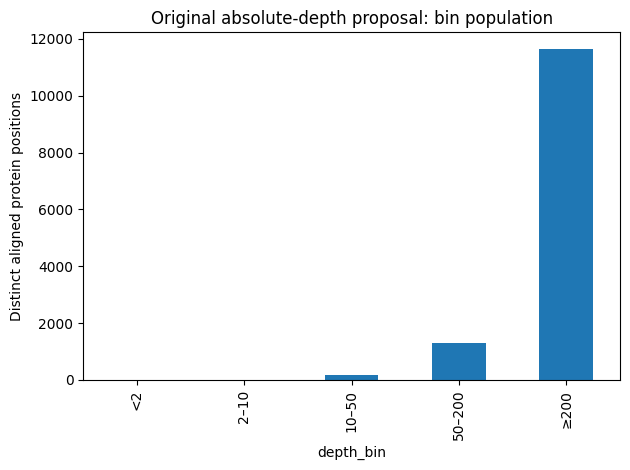

# Step B Path-C — Frozen bins + confound report (UniRef→ProteinGym v1.3 MSAs, theta=0.2)

**Date:** 2026-06-10. SCREEN/PREP ONLY — no AM scoring. Residue unit = distinct (accession, target_pos).
Per-column DEPTH = theta=0.2 weighted Neff (self-computed via 80%-id clustering; validated vs MSA_N_eff).
Per-column OCCUPANCY = raw non-gap fraction. 17,536 assay-positions → 13,115 aligned distinct
protein-positions + 1,774 insert-state (ProteinGym sub-threshold = unalignable hard end).

## DEPTH axis — original absolute edges FAIL; quantile edges PASS (but protein-limited)
Realized per-column Neff: min~0, p10=168, p25=495, **median=4799**, p75=11836, max=522197.
The specified absolute edges (<2/2-10/10-50/50-200/≥200) are far below this scale → **89% in ≥200**,
and the hard bins are degenerate/confounded:
- `<2`: 6 residues, **1 protein** (HXK4) → confounded
- `2-10`: 7 residues, 2 proteins (CAR11 71%) → confounded
- `10-50`: 166 residues, 8 proteins (CAR11 82%) → confounded

With **quantile

In [7]:
import numpy as np
import matplotlib.pyplot as plt
f=pd.read_csv(Path.cwd()/'inputs/axis3_pathC_percolumn_FROZEN.tsv',sep='\t')
u=f.loc[f.low_cov_insert==0].drop_duplicates(['accession','target_pos']).copy()
u['absolute_depth_bin']=pd.cut(u.neff_theta02,[-np.inf,2,10,50,200,np.inf],right=False,labels=['<2','2–10','10–50','50–200','≥200'])
rows=[]
for lev,g in u.groupby('absolute_depth_bin',observed=True):
    counts=g.accession.value_counts()
    rows.append(dict(depth_bin=str(lev),positions=len(g),proteins=g.accession.nunique(),largest_protein_fraction=counts.iloc[0]/len(g)))
diagnostic=pd.DataFrame(rows);display(diagnostic)
ax=diagnostic.plot.bar(x='depth_bin',y='positions',legend=False,title='Original absolute-depth proposal: bin population')
ax.set_ylabel('Distinct aligned protein positions');plt.tight_layout();plt.show()
print((Path.cwd()/'retained/STEP_B_PATHC_REPORT.md').read_text())


## Original processing, individual measurements, curves and controls

The following cells retain the supplied sample-level replay. Calculation cells use individual records; archived aggregate results are comparison targets. Any platform-specific reuse of recorded upstream outputs is printed explicitly.

# Effective alignment depth

This entry focuses on axis 3 of the original primary investigation. Its shared raw-input, individual-score and control calculations are retained below. **Historical decision:** rejected; unchanged.

- **1. Dataset and split:** 73 raw assay files; 273,135 single-mutant records; original offset/WT checks reproduce 270,572 scored variants in 72 assays and 63 proteins. No independent split recorded.
- **2. Axis and levels:** All 66 exact original alignments reclustered with original MMseqs binary/parameters. All occupancy values, insert flags and depth bins match; 65 weighted-feature sets match exactly, while OTU7A differs at 37 positions. Original and rebuilt tracks are both evaluated.
- **3. Model evaluation:** No standalone effective-depth performance curve was accepted or added; this entry reproduces the original insufficient-protein gate.
- **4. Curve and uncertainty:** Absolute-depth support counts reproduce the one- and two-protein shallowest levels. Every independently rebuilt depth-bin assignment matches; no unsupported depth-performance curve added.
- **5. Controls and confirmation:** High-depth subset, original PSSM/BLOSUM, dynamic range and paired sign checks reproduced; same-dataset controls, no independent confirmation cohort

# AlphaMissense primary investigation: sample-level occupancy analysis

This notebook reconstructs the original 270,572 scored variants in 72 assays from the 73 original ProteinGym files and a hash-verified subset of public AlphaMissense predictions. It reproduces the original curves, 5,000-assay bootstrap intervals and baseline, depth and experimental-range controls. No fresh AlphaMissense inference or independent confirmation cohort is claimed.

**Upstream recovery:** all 66 original alignments, original feature-construction programs and original MMseqs binary are now included. They were actually rerun on Linux. Occupancy, insert flags and depth-bin membership match at every assayed position. All weighted features match for 65 alignments; OTU7A differs at 37 aligned positions in effective depth and PSSM counts. A second identical-setting execution repeats the fresh arrays. The cause of the historical difference remains unresolved.

This notebook preserves the exact archived-feature track so historical outputs remain reproducible. The accompanying [upstream reconstruction notebook](../upstream_checks/upstream_reconstruction.ipynb) executes the raw-alignment chain on Linux (or verifies the recorded Linux outputs on macOS), reconstructs every feature row and quantifies the downstream effect of the OTU7A discrepancy. Original and newly rebuilt feature tables remain separate.

The earlier ClinVar depth and population screens are also recovered and are executed in `axis-1.ipynb` and `axis-2.ipynb`; they use their own original clinical benchmark, not this DMS cohort.

## Raw alignment reconstruction and its exact validation boundary

The next section is the executed upstream notebook. Its platform check is explicit: the supplied Linux binary runs on Linux x86-64; other platforms use its recorded, hash-verified output arrays.

In [8]:
from pathlib import Path
import os
PRIMARY_REPLAY_DIR=Path.cwd()
os.chdir(PRIMARY_REPLAY_DIR.parent/'upstream_checks')

# Primary AlphaMissense: raw alignment-to-result reproduction

All **66 original alignment files** and the original `build_axes.py`, `build_pssm.py` and MMseqs executable were recovered. The archive members are byte-identical to the alignments already included in the Opus r2 reference archive; their exact member hashes are included here, and the optional public download recipe restores them without the duplicate563MB archive. All 66 were actually reclustered using the original 80% identity, 80% coverage, `cov-mode=1`, 16-thread parameters. Cluster membership generates inverse-cluster-size sequence weights; those weights generate per-column depth and amino-acid counts. Occupancy is the unweighted non-gap fraction.

**Result:** 65 alignments reproduce every stored feature exactly at the historical precision. For OTU7A, 37 aligned positions have slightly different depth and weighted amino-acid counts. Occupancy, insert flags and assigned depth bins match everywhere. A second identical-setting OTU7A execution exactly repeats the new arrays; the cause of the historical mismatch is unresolved. This notebook quantifies the downstream effect without changing the preserved historical result.

This portable checkout uses the hash-verified outputs of the recorded Linux execution by default on every platform. Set `REBUILD_ALIGNMENTS=True` explicitly after downloading the66 exact public MSA members to execute the original Linux x86-64 constructor. The subsequent table construction, original scoring, bootstrap and comparisons execute in either environment. No fresh AlphaMissense inference or independent biological confirmation is claimed.

In [9]:
from pathlib import Path
import json,hashlib,platform,sys
import numpy as np,pandas as pd
from IPython.display import display
ROOT=Path.cwd();BUNDLE=ROOT.parent;INPUT=BUNDLE/'am-primary/inputs';EXPECTED=BUNDLE/'am-primary/expected'
expected={x['filename']:x['sha256'] for x in json.loads((ROOT/'opus_r2_msa_member_hashes.json').read_text())}
if REBUILD_ALIGNMENTS:
    # The explicit earlier opt-in downloads/verifies all66 members and runs the
    # original constructor. It is never enabled merely by running on Linux.
    RESULT=ROOT/'rebuilt/results';events=json.loads((ROOT/'rebuilt/events.json').read_text())
    print('Using fresh original-parameter alignment reconstruction requested above.')
else:
    RESULT=ROOT/'results';events=json.loads((ROOT/'events.json').read_text())
    print('Using recorded, hash-verified Linux alignment reconstruction arrays; no fresh clustering in this default run.')
done={x['msa']:x for x in events if x['kind']=='features_complete'};assert set(done)==set(expected)
for name,item in done.items():assert hashlib.sha256((RESULT/(name+'.npz')).read_bytes()).hexdigest()==item['output_sha256'],name
print('All66 recorded array outputs verified. Raw alignment member hashes and public download recipe are supplied separately.')
display(pd.DataFrame([json.loads((ROOT/'EXECUTION_ENVIRONMENT.json').read_text())]))


Using recorded, hash-verified Linux alignment reconstruction arrays; no fresh clustering in this default run.
All66 recorded array outputs verified. Raw alignment member hashes and public download recipe are supplied separately.


,platform,python,numpy,cpu_count,mmseqs_version,source_mount_readonly,portable_runner_test
0,Linux-6.1.0-54-cloud-amd64-x86_64-with-glibc2.36,3.11.2,2.1.2,16,fd711934753052544df18fa1dff8c762d6fe2188,True,"[{'msa': 'CD19_HUMAN_2023-10-12_b01.a2m.npz', ..."


## Reconstruct the complete per-position inputs

The mapping uses the exact original assay metadata and DMS substitutions. It preserves source order, fragment coordinates, insert handling, depth edges and rounding. Original stored feature values are used only as validation targets.

In [10]:
from materialize_features import materialize
OUT=ROOT/'reconstructed'
record=materialize(BUNDLE,RESULT,OUT);assert record['axis_rows']==17536 and record['pssm_rows']==15478
old_axis=pd.read_csv(INPUT/'axis3_pathC_percolumn_FROZEN.tsv',sep='\t');new_axis=pd.read_csv(OUT/'axis3_pathC_percolumn_FROZEN.tsv',sep='\t')
old_counts=pd.read_csv(INPUT/'pssm_counts.tsv',sep='\t');new_counts=pd.read_csv(OUT/'pssm_counts.tsv',sep='\t')
for field in ['assay','accession','gene','assay_family','target_pos','occupancy','low_cov_insert','depth_bin','n_variants']:
    pd.testing.assert_series_equal(old_axis[field],new_axis[field],check_exact=True)
axis_changed=(old_axis.ne(new_axis)&~(old_axis.isna()&new_axis.isna())).any(axis=1)
counts_changed=(old_counts.ne(new_counts)&~(old_counts.isna()&new_counts.isna())).any(axis=1)
comparison=dict(axis_rows=len(old_axis),pssm_rows=len(old_counts),axis_rows_changed=int(axis_changed.sum()),count_rows_changed=int(counts_changed.sum()),all_occupancy_flags_levels_exact=True,
    affected_assays=old_axis.loc[axis_changed,'assay'].unique().tolist(),max_depth_change=float((old_axis.neff_theta02-new_axis.neff_theta02).abs().max()),max_amino_acid_count_change=float((old_counts.iloc[:,3:]-new_counts.iloc[:,3:]).abs().to_numpy().max()))
assert comparison['axis_rows_changed']==comparison['count_rows_changed']==37
assert all('OTU7A' in a for a in comparison['affected_assays'])
(OUT/'feature_comparison.json').write_text(json.dumps(comparison,indent=2));display(pd.DataFrame([comparison]))
old_axis.loc[axis_changed].assign(new_effective_depth=new_axis.loc[axis_changed,'neff_theta02'].to_numpy()).to_csv(OUT/'differing_positions.csv',index=False)


,axis_rows,pssm_rows,axis_rows_changed,count_rows_changed,all_occupancy_flags_levels_exact,affected_assays,max_depth_change,max_amino_acid_count_change
0,17536,15478,37,37,True,[OTU7A_HUMAN_Tsuboyama_2023_2L2D],10.967,24.2003


## Original sample scoring and uncertainty from rebuilt features

These are the original programs with input/output paths redirected. The full set of original scored variants, fixed occupancy thresholds and original 5,000-assay bootstrap are unchanged. Newly rebuilt features are used here; the ordinary primary notebooks preserve the archived feature track separately.

In [11]:
#!/usr/bin/env python3
"""SPECTRA Axis-3 AM scoring (Path A, occupancy axis).
Join AM pathogenicity -> DMS single-mutant fitness for the 73-assay panel, then compute
per-assay |Spearman(AM, DMS)| WITHIN each occupancy bin and aggregate across assays.
Bins are FROZEN (stepB/axis3_pathC_percolumn_FROZEN.tsv) -- no model output in bin defs.
Accuracy metric = |Spearman| (AM predicts pathogenicity = anti-fitness; magnitude = accuracy,
sign aligned within-assay across bins). New files only; no overwrites. NO figure."""
import csv, gzip, statistics
from collections import defaultdict
import numpy as np

BASE=str(BUNDLE/"am-primary")
PG=str(INPUT/"proteingym"); STEPB=str(OUT)
AMFILE=str(INPUT/"official_scores_64_proteins.tsv.gz")
MIN_VAR=20  # min single-mutant variants per (assay,bin) for a stable Spearman

# ---------- tie-aware Spearman (numpy only) ----------
def rankavg(a):
    a=np.asarray(a,float); n=len(a)
    order=np.argsort(a,kind="mergesort")
    ranks=np.empty(n); ranks[order]=np.arange(n,dtype=float)
    sa=a[order]; i=0
    while i<n:
        j=i
        while j+1<n and sa[j+1]==sa[i]: j+=1
        if j>i: ranks[order[i:j+1]]=(i+j)/2.0
        i=j+1
    return ranks
def spearman(x,y):
    if len(x)<3: return float("nan")
    rx=rankavg(x); ry=rankavg(y); rx=rx-rx.mean(); ry=ry-ry.mean()
    den=np.sqrt((rx*rx).sum()*(ry*ry).sum())
    return float((rx*ry).sum()/den) if den>0 else float("nan")

# ---------- 1. panel ----------
assays={}; accs=set()
with open(f"{PG}/kept_assays_verified.tsv") as fh:
    for r in csv.DictReader(fh,delimiter="\t"):
        acc=r["resolved_accession"].strip()
        assays[r["DMS_id"]]={"acc":acc,"tseq":r["target_seq"].strip(),
                             "dms":r["DMS_filename"].strip(),"gene":r.get("UniProt_ID","").strip()}
        accs.add(acc)
print(f"panel: {len(assays)} assays, {len(accs)} distinct accessions")

# ---------- 2. AM lookup (stream gz, keep only our accessions) ----------
am=defaultdict(dict); amwt=defaultdict(dict)
nrows=0
with gzip.open(AMFILE,"rt") as fh:
    for line in fh:
        if line[0]=="#": continue
        if line[:10]=="uniprot_id": continue
        p=line.rstrip("\n").split("\t")
        if len(p)<3: continue
        acc=p[0]
        if acc not in accs: continue
        var=p[1]; wt=var[0]; mut=var[-1]
        try: pos=int(var[1:-1])
        except: continue
        am[acc][(pos,mut)]=float(p[2]); amwt[acc][pos]=wt; nrows+=1
print(f"AM rows kept for our accessions: {nrows}; accessions with AM data: {len(am)}/{len(accs)}")
missing_am=[a for a in accs if a not in am]
if missing_am: print(f"  accessions with NO AM data: {missing_am}")

def build_canon(acc):
    d=amwt.get(acc,{})
    if not d: return ""
    L=max(d)
    return "".join(d.get(i,"X") for i in range(1,L+1))

# ---------- 3. join AM <- DMS single mutants ----------
records=[]            # (assay, acc, pos, dms, am)
cov=[]                # per-assay coverage diagnostics
for aid,info in assays.items():
    acc=info["acc"]; tseq=info["tseq"]
    canon=build_canon(acc)
    offset=canon.find(tseq) if (canon and tseq) else -1
    n_single=n_scored=n_offfail=n_wtmis=n_nolookup=0
    try:
        fh=open(f"{PG}/dms_final_73/{info['dms']}")
    except FileNotFoundError:
        cov.append((aid,acc,0,0,-1,0,0,"FILE_MISSING")); continue
    for r in csv.DictReader(fh):
        mut=r["mutant"].strip()
        if ":" in mut: continue
        n_single+=1
        wt=mut[0]; mt=mut[-1]
        try: pos=int(mut[1:-1]); dms=float(r["DMS_score"])
        except: continue
        if offset<0: n_offfail+=1; continue
        cpos=offset+pos
        if amwt[acc].get(cpos)!=wt: n_wtmis+=1; continue
        s=am[acc].get((cpos,mt))
        if s is None: n_nolookup+=1; continue
        n_scored+=1; records.append((aid,acc,pos,dms,s))
    fh.close()
    status="OK" if offset>=0 else "OFFSET_FAIL"
    cov.append((aid,acc,n_single,n_scored,n_offfail,n_wtmis,n_nolookup,status))

tot_single=sum(c[2] for c in cov); tot_scored=sum(c[3] for c in cov)
print(f"\nJOIN: total single mutants={tot_single}  AM-scored={tot_scored} ({tot_scored/tot_single:.1%})")

# ---------- 4. frozen bins ----------
binmap={}
with open(f"{STEPB}/axis3_pathC_percolumn_FROZEN.tsv") as fh:
    for r in csv.DictReader(fh,delimiter="\t"):
        ins=r["low_cov_insert"]=="1"
        occ=r["occupancy"].strip(); neff=r["neff_theta02"].strip()
        binmap[(r["assay"],int(r["target_pos"]))]={
            "occ":(float(occ) if occ else float("nan")),"insert":ins,
            "neff":(float(neff) if neff else float("nan"))}

n_scored_binned=sum(1 for (aid,acc,pos,dms,s) in records if (aid,pos) in binmap)
print(f"AM-scored variants WITH a frozen bin: {n_scored_binned}/{tot_scored}")

# ---------- 5. aggregation engine ----------
def aggregate(selector):
    per={}
    for (aid,acc,pos,dms,s) in records:
        b=binmap.get((aid,pos))
        if b is None or not selector(b): continue
        per.setdefault(aid,[]).append((s,dms))
    rows=[]
    for aid,pairs in per.items():
        if len(pairs)<MIN_VAR: continue
        a=[p[0] for p in pairs]; d=[p[1] for p in pairs]
        rho=spearman(a,d)
        if rho==rho: rows.append((aid,assays[aid]["acc"],len(pairs),abs(rho),rho))
    if not rows:
        return {"n_assays":0,"n_prot":0,"n_var":0,"wmean":float("nan"),
                "umean":float("nan"),"median":float("nan"),"rows":[]}
    tv=sum(r[2] for r in rows)
    return {"n_assays":len(rows),"n_prot":len(set(r[1] for r in rows)),"n_var":tv,
            "wmean":sum(r[2]*r[3] for r in rows)/tv,
            "umean":statistics.mean(r[3] for r in rows),
            "median":statistics.median(r[3] for r in rows),"rows":rows}

# selectors
def s_coarse_hard(b): return b["insert"] or (b["occ"]<=0.9)
def s_coarse_easy(b): return (not b["insert"]) and b["occ"]>0.9
QE=[0.945,0.987,0.998,0.999]
def qbin(occ):
    return min(sum(1 for e in QE if occ>e),4)
def s_q(k):
    return lambda b: (not b["insert"]) and qbin(b["occ"])==k
def s_insert(b): return b["insert"]
def s_deep_lowocc(thr):
    return lambda b: (not b["insert"]) and b["neff"]>=200 and b["occ"]<thr
def s_deep_highocc(b): return (not b["insert"]) and b["neff"]>=200 and b["occ"]>=0.9

coarse_hard=aggregate(s_coarse_hard); coarse_easy=aggregate(s_coarse_easy)
qres={k:aggregate(s_q(k)) for k in range(5)}
insert_res=aggregate(s_insert)
d05=aggregate(s_deep_lowocc(0.5)); d07=aggregate(s_deep_lowocc(0.7)); dhi=aggregate(s_deep_highocc)
overall=aggregate(lambda b: True)

# ---------- 6. write report ----------
def fmt(d): return f"{d['wmean']:.3f}" if d['n_assays'] else "n/a"
def line(lbl,d):
    if not d["n_assays"]: return f"| {lbl} | 0 | 0 | 0 | n/a | n/a | n/a |"
    return (f"| {lbl} | {d['n_assays']} | {d['n_prot']} | {d['n_var']} | "
            f"{d['wmean']:.3f} | {d['umean']:.3f} | {d['median']:.3f} |")

gap=(coarse_easy["wmean"]-coarse_hard["wmean"]) if (coarse_hard["n_assays"] and coarse_easy["n_assays"]) else float("nan")

out=[]
out.append("# Step B — Axis-3 AM scoring results (Path A, occupancy axis)\n")
out.append("**Date:** 2026-06-10. AM AlphaMissense_aa_substitutions.tsv.gz joined to ProteinGym v1.3 "
           "DMS single mutants (73 assays). Bins FROZEN before scoring "
           "(`stepB/axis3_pathC_percolumn_FROZEN.tsv`). Accuracy metric = **|Spearman(AM, DMS_score)|** "
           "per (assay,bin); aggregated across assays. `wmean` = variant-count-weighted mean |rho|; "
           f"`umean` = unweighted mean; `median` = median. Min variants/(assay,bin) = {MIN_VAR}.\n")
out.append("## 0. Join coverage\n")
out.append(f"- Total single mutants (no-colon) across 73 assays: **{tot_single}**")
out.append(f"- AM-scored: **{tot_scored}** ({tot_scored/tot_single:.1%})")
out.append(f"- AM-scored AND within a frozen occupancy bin (usable for SPC): **{n_scored_binned}**")
if missing_am: out.append(f"- Accessions with NO AM data: {missing_am}")
out.append(f"- Overall |Spearman| (all binned variants, no split): wmean={overall['wmean']:.3f} "
           f"over {overall['n_assays']} assays / {overall['n_prot']} proteins / {overall['n_var']} variants\n")
# poor-coverage assays
poor=sorted([c for c in cov if c[2]>0 and c[3]/c[2]<0.90], key=lambda c:c[3]/c[2])
out.append("### Assays with <90% AM join coverage")
if poor:
    out.append("| assay | acc | n_single | n_scored | cov | offfail | wt_mismatch | no_AM_var | status |")
    out.append("|---|---|---|---|---|---|---|---|---|")
    for c in poor:
        out.append(f"| {c[0]} | {c[1]} | {c[2]} | {c[3]} | {c[3]/c[2]:.0%} | {c[4]} | {c[5]} | {c[6]} | {c[7]} |")
else:
    out.append("None — all 73 assays ≥90% AM join coverage.")
out.append("")

out.append("## 1. Coarse headline — hard vs easy (occupancy)\n")
out.append("Hard = insert-state OR aligned occ≤0.9 ; Easy = aligned occ>0.9.\n")
out.append("| bin | n_assays | n_proteins | n_variants | wmean \\|rho\\| | umean | median |")
out.append("|---|---|---|---|---|---|---|")
out.append(line("HARD (insert + occ≤0.9)",coarse_hard))
out.append(line("EASY (occ>0.9)",coarse_easy))
out.append("")
out.append(f"**Hard-vs-easy gap (easy_wmean − hard_wmean) = {gap:+.3f}**  "
           f"(positive = AM less accurate on hard columns).\n")

out.append("## 2. Quintile resolution — 5 occupancy bins (aligned) + insert-state\n")
out.append("| occ bin | range | n_assays | n_proteins | n_variants | wmean \\|rho\\| | umean | median |")
out.append("|---|---|---|---|---|---|---|---|")
rngs=["occ≤0.945","0.945–0.987","0.987–0.998","0.998–0.999","occ>0.999 (~1.0)"]
for k in range(5):
    d=qres[k]
    if d["n_assays"]:
        out.append(f"| q{k} | {rngs[k]} | {d['n_assays']} | {d['n_prot']} | {d['n_var']} | "
                   f"{d['wmean']:.3f} | {d['umean']:.3f} | {d['median']:.3f} |")
    else:
        out.append(f"| q{k} | {rngs[k]} | 0 | 0 | 0 | n/a | n/a | n/a |")
out.append(line("insert-state (hardest)",insert_res))
out.append("")

out.append("## 3. Interaction — deep (Neff≥200) AND low-occupancy vs deep high-occupancy\n")
out.append("Tests 'hard-to-align ≠ shallow': among columns with abundant homologs, does gappiness still degrade AM?\n")
out.append("| cell | n_assays | n_proteins | n_variants | wmean \\|rho\\| | umean | median |")
out.append("|---|---|---|---|---|---|---|")
out.append(line("DEEP & occ<0.5",d05))
out.append(line("DEEP & occ<0.7",d07))
out.append(line("DEEP & occ≥0.9 (reference)",dhi))
out.append("")
if dhi["n_assays"] and d07["n_assays"]:
    out.append(f"**Interaction gap (deep-high − deep&occ<0.7) = {dhi['wmean']-d07['wmean']:+.3f}**\n")

# per-assay dump for the coarse split (transparency)
out.append("## 4. Per-assay |rho| for the coarse split (transparency)\n")
out.append("| assay | acc | n_hard | rho_hard | n_easy | rho_easy |")
out.append("|---|---|---|---|---|---|")
hd={r[0]:(r[2],r[4]) for r in coarse_hard["rows"]}
ed={r[0]:(r[2],r[4]) for r in coarse_easy["rows"]}
for aid in sorted(set(hd)|set(ed)):
    nh,rh=hd.get(aid,(0,float("nan"))); ne,re=ed.get(aid,(0,float("nan")))
    out.append(f"| {aid} | {assays[aid]['acc']} | {nh} | "
               f"{rh:.3f} | {ne} | {re:.3f} |")

with open(f"{STEPB}/STEP_B_SCORING_RESULTS.md","w") as fh:
    fh.write("\n".join(out)+"\n")

# also a machine-readable per-assay-bin TSV
with open(f"{STEPB}/axis3_SPC_perassay_bins.tsv","w") as fh:
    fh.write("bin_label\tassay\tacc\tn_variants\tabs_rho\tsigned_rho\n")
    for lbl,d in [("coarse_hard",coarse_hard),("coarse_easy",coarse_easy),
                  ("q0",qres[0]),("q1",qres[1]),("q2",qres[2]),("q3",qres[3]),("q4",qres[4]),
                  ("insert",insert_res),("deep_occ<0.5",d05),("deep_occ<0.7",d07),
                  ("deep_occ>=0.9",dhi)]:
        for r in d["rows"]:
            fh.write(f"{lbl}\t{r[0]}\t{r[1]}\t{r[2]}\t{r[3]:.4f}\t{r[4]:.4f}\n")

# console summary
print("\n===== SUMMARY =====")
print(f"COARSE  hard: wmean|rho|={fmt(coarse_hard)} (na={coarse_hard['n_assays']},np={coarse_hard['n_prot']},nv={coarse_hard['n_var']})")
print(f"COARSE  easy: wmean|rho|={fmt(coarse_easy)} (na={coarse_easy['n_assays']},np={coarse_easy['n_prot']},nv={coarse_easy['n_var']})")
print(f"GAP (easy-hard) = {gap:+.3f}")
for k in range(5):
    d=qres[k]; print(f"q{k} {rngs[k]:18s}: wmean|rho|={fmt(d)} (na={d['n_assays']},np={d['n_prot']},nv={d['n_var']})")
print(f"insert      : wmean|rho|={fmt(insert_res)} (na={insert_res['n_assays']},np={insert_res['n_prot']},nv={insert_res['n_var']})")
print(f"DEEP&occ<0.5: wmean|rho|={fmt(d05)} (na={d05['n_assays']},np={d05['n_prot']},nv={d05['n_var']})")
print(f"DEEP&occ<0.7: wmean|rho|={fmt(d07)} (na={d07['n_assays']},np={d07['n_prot']},nv={d07['n_var']})")
print(f"DEEP&occ>=.9: wmean|rho|={fmt(dhi)} (na={dhi['n_assays']},np={dhi['n_prot']},nv={dhi['n_var']})")
print("\nWROTE stepB/STEP_B_SCORING_RESULTS.md and stepB/axis3_SPC_perassay_bins.tsv")
print("DONE")


panel: 73 assays, 64 distinct accessions


AM rows kept for our accessions: 955738; accessions with AM data: 64/64



JOIN: total single mutants=273135  AM-scored=270572 (99.1%)
AM-scored variants WITH a frozen bin: 270572/270572



===== SUMMARY =====
COARSE  hard: wmean|rho|=0.349 (na=65,np=56,nv=63148)
COARSE  easy: wmean|rho|=0.476 (na=68,np=59,nv=207424)
GAP (easy-hard) = +0.128
q0 occ≤0.945         : wmean|rho|=0.395 (na=62,np=53,nv=45606)
q1 0.945–0.987       : wmean|rho|=0.418 (na=61,np=53,nv=49852)
q2 0.987–0.998       : wmean|rho|=0.443 (na=62,np=54,nv=57338)
q3 0.998–0.999       : wmean|rho|=0.506 (na=56,np=49,nv=26849)
q4 occ>0.999 (~1.0)  : wmean|rho|=0.515 (na=60,np=53,nv=59838)
insert      : wmean|rho|=0.266 (na=48,np=44,nv=30910)
DEEP&occ<0.5: wmean|rho|=0.386 (na=19,np=17,nv=2342)
DEEP&occ<0.7: wmean|rho|=0.305 (na=28,np=25,nv=5438)
DEEP&occ>=.9: wmean|rho|=0.475 (na=58,np=50,nv=192059)

WROTE stepB/STEP_B_SCORING_RESULTS.md and stepB/axis3_SPC_perassay_bins.tsv
DONE


In [12]:
#!/usr/bin/env python3
"""Score AM vs AM-INDEPENDENT baselines (site-independent PSSM log-odds, BLOSUM62) on the SAME
frozen occupancy bins, plus a DMS-signal control (within-assay DMS spread per bin). Answers:
does AM degrade MORE steeply than baselines (AM-specific), or do all degrade together
(intrinsic position difficulty)? And is DMS signal collapsing at gappy columns?
Metric = per-assay |Spearman(pred, DMS)|, variant-weighted across assays, 95% bootstrap CI over assays.
New files only."""
import csv, gzip, math
from collections import defaultdict
import numpy as np
from scipy.stats import spearmanr
from Bio.Align import substitution_matrices

BASE=str(BUNDLE/"am-primary"); PG=str(INPUT/"proteingym"); STEPB=str(OUT)
AMFILE=str(INPUT/"official_scores_64_proteins.tsv.gz")
MIN_VAR=20; AA="ACDEFGHIKLMNPQRSTVWY"; BETA=0.5
B62=substitution_matrices.load("BLOSUM62")
def blosum(w,m):
    try: return float(B62[(w,m)])
    except:
        try: return float(B62[(m,w)])
        except: return None

# ---------- panel ----------
assays={}; accs=set()
with open(f"{PG}/kept_assays_verified.tsv") as fh:
    for r in csv.DictReader(fh,delimiter="\t"):
        acc=r["resolved_accession"].strip()
        assays[r["DMS_id"]]={"acc":acc,"tseq":r["target_seq"].strip(),"dms":r["DMS_filename"].strip()}
        accs.add(acc)

# ---------- AM lookup ----------
am=defaultdict(dict); amwt=defaultdict(dict)
with gzip.open(AMFILE,"rt") as fh:
    for line in fh:
        if line[0]=="#" or line[:10]=="uniprot_id": continue
        p=line.rstrip("\n").split("\t")
        if len(p)<3 or p[0] not in accs: continue
        v=p[1];
        try: pos=int(v[1:-1])
        except: continue
        am[p[0]][(pos,v[-1])]=float(p[2]); amwt[p[0]][pos]=v[0]
def canon(acc):
    d=amwt.get(acc,{});
    return "".join(d.get(i,"X") for i in range(1,max(d)+1)) if d else ""
print(f"AM accessions loaded: {len(am)}/{len(accs)}",flush=True)

# ---------- PSSM lookup ----------
pssm={}   # (assay,pos) -> dict aa->count, plus tot
with open(f"{STEPB}/pssm_counts.tsv") as fh:
    rd=csv.reader(fh,delimiter="\t"); hdr=next(rd)
    aacols=hdr[3:]
    for row in rd:
        assay=row[0]; pos=int(row[1])
        cnt={aacols[i]:float(row[3+i]) for i in range(len(aacols))}
        pssm[(assay,pos)]=cnt
def pssm_score(assay,pos,w,m):
    c=pssm.get((assay,pos))
    if c is None or w not in c or m not in c: return None
    return math.log((c[m]+BETA)/(c[w]+BETA))
print(f"PSSM positions loaded: {len(pssm)}",flush=True)

# ---------- frozen bins ----------
binmap={}
with open(f"{STEPB}/axis3_pathC_percolumn_FROZEN.tsv") as fh:
    for r in csv.DictReader(fh,delimiter="\t"):
        ins=r["low_cov_insert"]=="1"; occ=r["occupancy"].strip(); neff=r["neff_theta02"].strip()
        binmap[(r["assay"],int(r["target_pos"]))]={"occ":float(occ) if occ else float("nan"),
            "insert":ins,"neff":float(neff) if neff else float("nan")}

# ---------- join ----------
rec=[]  # (assay,acc,pos,dms,am,blosum,pssm)
for aid,info in assays.items():
    acc=info["acc"]; cn=canon(acc); off=cn.find(info["tseq"]) if (cn and info["tseq"]) else -1
    with open(f"{PG}/dms_final_73/{info['dms']}") as fh:
        for r in csv.DictReader(fh):
            mut=r["mutant"].strip()
            if ":" in mut: continue
            w=mut[0]; m=mut[-1]
            try: pos=int(mut[1:-1]); dms=float(r["DMS_score"])
            except: continue
            if off<0: continue
            cpos=off+pos
            if amwt[acc].get(cpos)!=w: continue
            a=am[acc].get((cpos,m))
            if a is None: continue
            rec.append((aid,acc,pos,dms,a,blosum(w,m),pssm_score(aid,pos,w,m)))
print(f"joined variants: {len(rec)}",flush=True)

# predictor extractors (index into rec tuple)
PRED={"AM":4,"BLOSUM62":5,"PSSM":6}

# ---------- bins ----------
QE=[0.945,0.987,0.998,0.999]
def qbin(o): return min(sum(1 for e in QE if o>e),4)
BINSELS={
 "insert":lambda b: b["insert"],
 "q0":lambda b:(not b["insert"]) and qbin(b["occ"])==0,
 "q1":lambda b:(not b["insert"]) and qbin(b["occ"])==1,
 "q2":lambda b:(not b["insert"]) and qbin(b["occ"])==2,
 "q3":lambda b:(not b["insert"]) and qbin(b["occ"])==3,
 "q4":lambda b:(not b["insert"]) and qbin(b["occ"])==4,
 "deep_occ>=0.9":lambda b:(not b["insert"]) and b["neff"]>=200 and b["occ"]>=0.9,
 "deep_occ<0.7":lambda b:(not b["insert"]) and b["neff"]>=200 and b["occ"]<0.7,
}

def agg(pred_idx, binsel, B=5000, seed=42):
    per=defaultdict(list)
    for t in rec:
        v=t[pred_idx]
        if v is None: continue
        b=binmap.get((t[0],t[2]))
        if b is None or not binsel(b): continue
        per[t[0]].append((v,t[3]))
    rows=[]
    for aid,pairs in per.items():
        if len(pairs)<MIN_VAR: continue
        x=[p[0] for p in pairs]; y=[p[1] for p in pairs]
        rho=spearmanr(x,y).correlation
        if rho==rho: rows.append((aid,assays[aid]["acc"],len(pairs),abs(rho)))
    if not rows: return None
    nv=np.array([r[2] for r in rows],float); ar=np.array([r[3] for r in rows])
    wmean=float((nv*ar).sum()/nv.sum())
    rng=np.random.default_rng(seed); n=len(rows); idx=rng.integers(0,n,size=(B,n))
    bm=(nv[idx]*ar[idx]).sum(1)/nv[idx].sum(1); lo,hi=np.percentile(bm,[2.5,97.5])
    return dict(wmean=wmean,lo=float(lo),hi=float(hi),na=n,nprot=len(set(r[1] for r in rows)),nv=int(nv.sum()))

# ---------- DMS signal control: within-assay DMS spread per bin (normalized) ----------
ABINS=["insert","q0","q1","q2","q3","q4"]
dms_by=defaultdict(lambda: defaultdict(list))  # assay -> bin -> [dms]
alld=defaultdict(list)
for t in rec:
    b=binmap.get((t[0],t[2]))
    if b is None: continue
    for bl in ABINS:
        if BINSELS[bl](b): dms_by[t[0]][bl].append(t[3]); break
    alld[t[0]].append(t[3])
sig={}
for bl in ABINS:
    rels=[]; stds=[]
    for aid in dms_by:
        v=dms_by[aid].get(bl,[])
        if len(v)<MIN_VAR: continue
        s=float(np.std(v)); o=float(np.std(alld[aid]))
        stds.append(s)
        if o>0: rels.append(s/o)
    sig[bl]=dict(med_std=float(np.median(stds)) if stds else float("nan"),
                 mean_rel=float(np.mean(rels)) if rels else float("nan"),na=len(stds))

# ---------- write ----------
with open(f"{STEPB}/axis3_baselines_binstats.tsv","w") as fh:
    fh.write("predictor\tbin\twmean_absrho\tci2.5\tci97.5\tn_assays\tn_proteins\tn_variants\n")
    for pname,pidx in PRED.items():
        for bl in ["insert","q0","q1","q2","q3","q4","deep_occ>=0.9","deep_occ<0.7"]:
            s=agg(pidx,BINSELS[bl])
            if s: fh.write(f"{pname}\t{bl}\t{s['wmean']:.4f}\t{s['lo']:.4f}\t{s['hi']:.4f}\t{s['na']}\t{s['nprot']}\t{s['nv']}\n")
            else: fh.write(f"{pname}\t{bl}\tNA\tNA\tNA\t0\t0\t0\n")
with open(f"{STEPB}/axis3_dms_signal_perbin.tsv","w") as fh:
    fh.write("bin\tmedian_within_assay_dms_std\tmean_relative_spread\tn_assays\n")
    for bl in ABINS:
        s=sig[bl]; fh.write(f"{bl}\t{s['med_std']:.4f}\t{s['mean_rel']:.4f}\t{s['na']}\n")

# ---------- console ----------
print("\n===== AM vs BASELINES (wmean |rho| per bin) =====")
print(f"{'bin':14s}{'AM':>20}{'PSSM':>20}{'BLOSUM62':>20}")
def cell(pidx,bl):
    s=agg(pidx,BINSELS[bl]);
    return f"{s['wmean']:.3f}[{s['lo']:.2f}-{s['hi']:.2f}]n{s['na']}" if s else "--"
for bl in ["insert","q0","q1","q2","q3","q4","deep_occ>=0.9","deep_occ<0.7"]:
    print(f"{bl:14s}{cell(4,bl):>20}{cell(6,bl):>20}{cell(5,bl):>20}")
print("\n===== DMS SIGNAL CONTROL (within-assay spread per bin) =====")
print(f"{'bin':10s}{'median_std':>14}{'mean_rel_spread':>18}{'n':>5}")
for bl in ABINS:
    s=sig[bl]; print(f"{bl:10s}{s['med_std']:>14.3f}{s['mean_rel']:>18.3f}{s['na']:>5}")
print("\nWROTE axis3_baselines_binstats.tsv, axis3_dms_signal_perbin.tsv")
print("DONE")


AM accessions loaded: 64/64


PSSM positions loaded: 15478


joined variants: 270572



===== AM vs BASELINES (wmean |rho| per bin) =====
bin                             AM                PSSM            BLOSUM62
insert         0.266[0.19-0.36]n48                  -- 0.119[0.08-0.16]n48


q0             0.395[0.31-0.46]n62 0.308[0.23-0.37]n62 0.156[0.12-0.19]n62


q1             0.418[0.37-0.47]n61 0.372[0.31-0.43]n61 0.196[0.17-0.23]n61


q2             0.443[0.39-0.49]n62 0.410[0.37-0.44]n62 0.221[0.19-0.25]n62


q3             0.506[0.45-0.56]n56 0.432[0.38-0.49]n56 0.230[0.19-0.27]n56


q4             0.515[0.48-0.55]n60 0.480[0.44-0.52]n60 0.244[0.22-0.27]n60


deep_occ>=0.9  0.475[0.44-0.51]n58 0.435[0.40-0.47]n58 0.213[0.19-0.24]n58
deep_occ<0.7   0.305[0.18-0.40]n28 0.274[0.20-0.35]n28 0.153[0.10-0.19]n28

===== DMS SIGNAL CONTROL (within-assay spread per bin) =====
bin           median_std   mean_rel_spread    n
insert             0.414             0.730   48
q0                 0.519             0.865   62
q1                 0.628             0.939   61
q2                 0.702             0.945   62
q3                 0.657             0.985   56
q4                 0.823             1.004   60

WROTE axis3_baselines_binstats.tsv, axis3_dms_signal_perbin.tsv
DONE


In [13]:
assert len(rec)==270572
old=pd.read_csv(EXPECTED/'axis3_baselines_binstats.tsv',sep='\t');new=pd.read_csv(OUT/'axis3_baselines_binstats.tsv',sep='\t')
changes=[]
for i,row in old.iterrows():
    for field in ['wmean_absrho','ci2.5','ci97.5']:
        a=row[field];b=new.loc[i,field]
        if pd.notna(a) and abs(a-b)>0:changes.append(dict(predictor=row.predictor,bin=row.bin,statistic=field,original=float(a),rebuilt=float(b),difference=float(b-a)))
change_table=pd.DataFrame(changes,columns=['predictor','bin','statistic','original','rebuilt','difference']);change_table.to_csv(OUT/'downstream_statistic_changes.csv',index=False)
for filename in ['axis3_SPC_perassay_bins.tsv','axis3_dms_signal_perbin.tsv']:
    a=pd.read_csv(EXPECTED/filename,sep='\t');b=pd.read_csv(OUT/filename,sep='\t');pd.testing.assert_frame_equal(a,b,check_exact=True)
assert all(x['predictor']=='PSSM' for x in changes)
summary=dict(rebuilt_scored_variants=len(rec),AM_per_assay_outputs_unchanged=True,DMS_dynamic_range_unchanged=True,changed_summary_statistics=len(changes),maximum_summary_change=max([abs(x['difference']) for x in changes],default=0.0),changed_predictors=sorted({x['predictor'] for x in changes}),independent_confirmation=False)
(OUT/'DOWNSTREAM_VALIDATION.json').write_text(json.dumps(summary,indent=2));display(pd.DataFrame([summary]));display(change_table)
# Preserve this freshly reconstructed lookup until the original-feature track
# has generated its individual records later in this same clean execution.
reconstructed_pssm_lookup=pssm
reconstructed_output=OUT


,rebuilt_scored_variants,AM_per_assay_outputs_unchanged,DMS_dynamic_range_unchanged,changed_summary_statistics,maximum_summary_change,changed_predictors,independent_confirmation
0,270572,True,True,1,0.0001,[PSSM],False


,predictor,bin,statistic,original,rebuilt,difference
0,PSSM,q3,ci2.5,0.3823,0.3824,0.0001


## Interpretation

The recovered upstream chain is executable. Its OTU7A difference is retained as a specific reproducibility limitation, with individual changed baseline values and its effect on aggregate estimates available above. It does not change the primary AlphaMissense per-assay results or the DMS dynamic-range control. The original archived track is preserved; this sensitivity is not a replacement scientific run or independent confirmation.

In [14]:
os.chdir(PRIMARY_REPLAY_DIR)
print('The archived-feature track below is preserved separately from the rebuilt-feature comparison above.')

The archived-feature track below is preserved separately from the rebuilt-feature comparison above.


In [15]:
from pathlib import Path
import json,hashlib,shutil,platform
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd();INPUT=ROOT/'inputs';EXPECTED=ROOT/'expected';OUT=ROOT/'recomputed';OUT.mkdir(exist_ok=True)
for item in json.loads((ROOT/'INPUT_MANIFEST.json').read_text()):
    if item['path'].startswith('inputs/clinvar/'):continue  # Separate clinical axes; not read by this DMS analysis.
    p=ROOT/item['path'];assert p.is_file() and hashlib.sha256(p.read_bytes()).hexdigest()==item['sha256'],item['path']
source=json.loads((INPUT/'official_score_subset_provenance.json').read_text())
assert source['source_sha256']=='bc18d954a9aa6b9efab8e40d6d1912e32b774906cd3846a1f51066588e9c176d'
assert source['selected_rows']==955738 and source['selected_proteins']==64
for name in ['axis3_pathC_percolumn_FROZEN.tsv','pssm_counts.tsv']:
    shutil.copyfile(INPUT/name,OUT/name)
print('All retained inputs and code verified; Python',platform.python_version())
display(pd.DataFrame([source]))


All retained inputs and code verified; Python 3.11.8


,source_url,source_sha256,source_bytes,source_rows,selected_proteins,selected_rows,selection,output_sha256
0,https://storage.googleapis.com/dm_alphamissens...,bc18d954a9aa6b9efab8e40d6d1912e32b774906cd3846...,1207278510,216175351,64,955738,All official scores for accessions in kept_ass...,1657bce1cad681b6755831da727ceb00b5ee9d0a024e27...


## 1–3. Exact samples, axis membership and individual evaluation

The original program below constructs canonical sequence coordinates from the wild-type residue in the official AlphaMissense table, finds the assay target sequence within that sequence, and shifts each fragment's variant positions by the exact substring offset. It checks the wild-type amino acid before joining the prediction. UBC9 has no accepted offset and its 2,563 variants are excluded, as in the original report.

The fixed occupancy thresholds are **0.945, 0.987, 0.998 and 0.999**, with a separate insert-state group. They are the thresholds actually used by the original scorer, not freshly recomputed quantiles. Effective depth ≥200 defines the high-depth controls. Each assay/bin needs at least 20 variants with a finite Spearman correlation. The program uses absolute within-assay Spearman and variant-count-weighted aggregation.

This cell is the recovered original program; only four filesystem locations are redirected to packaged inputs and a fresh output folder. No numerical logic changes.

In [16]:
#!/usr/bin/env python3
"""SPECTRA Axis-3 AM scoring (Path A, occupancy axis).
Join AM pathogenicity -> DMS single-mutant fitness for the 73-assay panel, then compute
per-assay |Spearman(AM, DMS)| WITHIN each occupancy bin and aggregate across assays.
Bins are FROZEN (stepB/axis3_pathC_percolumn_FROZEN.tsv) -- no model output in bin defs.
Accuracy metric = |Spearman| (AM predicts pathogenicity = anti-fitness; magnitude = accuracy,
sign aligned within-assay across bins). New files only; no overwrites. NO figure."""
import csv, gzip, statistics
from collections import defaultdict
import numpy as np

BASE=str(ROOT)
PG=str(INPUT/"proteingym"); STEPB=str(OUT)
AMFILE=str(INPUT/"official_scores_64_proteins.tsv.gz")
MIN_VAR=20  # min single-mutant variants per (assay,bin) for a stable Spearman

# ---------- tie-aware Spearman (numpy only) ----------
def rankavg(a):
    a=np.asarray(a,float); n=len(a)
    order=np.argsort(a,kind="mergesort")
    ranks=np.empty(n); ranks[order]=np.arange(n,dtype=float)
    sa=a[order]; i=0
    while i<n:
        j=i
        while j+1<n and sa[j+1]==sa[i]: j+=1
        if j>i: ranks[order[i:j+1]]=(i+j)/2.0
        i=j+1
    return ranks
def spearman(x,y):
    if len(x)<3: return float("nan")
    rx=rankavg(x); ry=rankavg(y); rx=rx-rx.mean(); ry=ry-ry.mean()
    den=np.sqrt((rx*rx).sum()*(ry*ry).sum())
    return float((rx*ry).sum()/den) if den>0 else float("nan")

# ---------- 1. panel ----------
assays={}; accs=set()
with open(f"{PG}/kept_assays_verified.tsv") as fh:
    for r in csv.DictReader(fh,delimiter="\t"):
        acc=r["resolved_accession"].strip()
        assays[r["DMS_id"]]={"acc":acc,"tseq":r["target_seq"].strip(),
                             "dms":r["DMS_filename"].strip(),"gene":r.get("UniProt_ID","").strip()}
        accs.add(acc)
print(f"panel: {len(assays)} assays, {len(accs)} distinct accessions")

# ---------- 2. AM lookup (stream gz, keep only our accessions) ----------
am=defaultdict(dict); amwt=defaultdict(dict)
nrows=0
with gzip.open(AMFILE,"rt") as fh:
    for line in fh:
        if line[0]=="#": continue
        if line[:10]=="uniprot_id": continue
        p=line.rstrip("\n").split("\t")
        if len(p)<3: continue
        acc=p[0]
        if acc not in accs: continue
        var=p[1]; wt=var[0]; mut=var[-1]
        try: pos=int(var[1:-1])
        except: continue
        am[acc][(pos,mut)]=float(p[2]); amwt[acc][pos]=wt; nrows+=1
print(f"AM rows kept for our accessions: {nrows}; accessions with AM data: {len(am)}/{len(accs)}")
missing_am=[a for a in accs if a not in am]
if missing_am: print(f"  accessions with NO AM data: {missing_am}")

def build_canon(acc):
    d=amwt.get(acc,{})
    if not d: return ""
    L=max(d)
    return "".join(d.get(i,"X") for i in range(1,L+1))

# ---------- 3. join AM <- DMS single mutants ----------
records=[]            # (assay, acc, pos, dms, am)
cov=[]                # per-assay coverage diagnostics
for aid,info in assays.items():
    acc=info["acc"]; tseq=info["tseq"]
    canon=build_canon(acc)
    offset=canon.find(tseq) if (canon and tseq) else -1
    n_single=n_scored=n_offfail=n_wtmis=n_nolookup=0
    try:
        fh=open(f"{PG}/dms_final_73/{info['dms']}")
    except FileNotFoundError:
        cov.append((aid,acc,0,0,-1,0,0,"FILE_MISSING")); continue
    for r in csv.DictReader(fh):
        mut=r["mutant"].strip()
        if ":" in mut: continue
        n_single+=1
        wt=mut[0]; mt=mut[-1]
        try: pos=int(mut[1:-1]); dms=float(r["DMS_score"])
        except: continue
        if offset<0: n_offfail+=1; continue
        cpos=offset+pos
        if amwt[acc].get(cpos)!=wt: n_wtmis+=1; continue
        s=am[acc].get((cpos,mt))
        if s is None: n_nolookup+=1; continue
        n_scored+=1; records.append((aid,acc,pos,dms,s))
    fh.close()
    status="OK" if offset>=0 else "OFFSET_FAIL"
    cov.append((aid,acc,n_single,n_scored,n_offfail,n_wtmis,n_nolookup,status))

tot_single=sum(c[2] for c in cov); tot_scored=sum(c[3] for c in cov)
print(f"\nJOIN: total single mutants={tot_single}  AM-scored={tot_scored} ({tot_scored/tot_single:.1%})")

# ---------- 4. frozen bins ----------
binmap={}
with open(f"{STEPB}/axis3_pathC_percolumn_FROZEN.tsv") as fh:
    for r in csv.DictReader(fh,delimiter="\t"):
        ins=r["low_cov_insert"]=="1"
        occ=r["occupancy"].strip(); neff=r["neff_theta02"].strip()
        binmap[(r["assay"],int(r["target_pos"]))]={
            "occ":(float(occ) if occ else float("nan")),"insert":ins,
            "neff":(float(neff) if neff else float("nan"))}

n_scored_binned=sum(1 for (aid,acc,pos,dms,s) in records if (aid,pos) in binmap)
print(f"AM-scored variants WITH a frozen bin: {n_scored_binned}/{tot_scored}")

# ---------- 5. aggregation engine ----------
def aggregate(selector):
    per={}
    for (aid,acc,pos,dms,s) in records:
        b=binmap.get((aid,pos))
        if b is None or not selector(b): continue
        per.setdefault(aid,[]).append((s,dms))
    rows=[]
    for aid,pairs in per.items():
        if len(pairs)<MIN_VAR: continue
        a=[p[0] for p in pairs]; d=[p[1] for p in pairs]
        rho=spearman(a,d)
        if rho==rho: rows.append((aid,assays[aid]["acc"],len(pairs),abs(rho),rho))
    if not rows:
        return {"n_assays":0,"n_prot":0,"n_var":0,"wmean":float("nan"),
                "umean":float("nan"),"median":float("nan"),"rows":[]}
    tv=sum(r[2] for r in rows)
    return {"n_assays":len(rows),"n_prot":len(set(r[1] for r in rows)),"n_var":tv,
            "wmean":sum(r[2]*r[3] for r in rows)/tv,
            "umean":statistics.mean(r[3] for r in rows),
            "median":statistics.median(r[3] for r in rows),"rows":rows}

# selectors
def s_coarse_hard(b): return b["insert"] or (b["occ"]<=0.9)
def s_coarse_easy(b): return (not b["insert"]) and b["occ"]>0.9
QE=[0.945,0.987,0.998,0.999]
def qbin(occ):
    return min(sum(1 for e in QE if occ>e),4)
def s_q(k):
    return lambda b: (not b["insert"]) and qbin(b["occ"])==k
def s_insert(b): return b["insert"]
def s_deep_lowocc(thr):
    return lambda b: (not b["insert"]) and b["neff"]>=200 and b["occ"]<thr
def s_deep_highocc(b): return (not b["insert"]) and b["neff"]>=200 and b["occ"]>=0.9

coarse_hard=aggregate(s_coarse_hard); coarse_easy=aggregate(s_coarse_easy)
qres={k:aggregate(s_q(k)) for k in range(5)}
insert_res=aggregate(s_insert)
d05=aggregate(s_deep_lowocc(0.5)); d07=aggregate(s_deep_lowocc(0.7)); dhi=aggregate(s_deep_highocc)
overall=aggregate(lambda b: True)

# ---------- 6. write report ----------
def fmt(d): return f"{d['wmean']:.3f}" if d['n_assays'] else "n/a"
def line(lbl,d):
    if not d["n_assays"]: return f"| {lbl} | 0 | 0 | 0 | n/a | n/a | n/a |"
    return (f"| {lbl} | {d['n_assays']} | {d['n_prot']} | {d['n_var']} | "
            f"{d['wmean']:.3f} | {d['umean']:.3f} | {d['median']:.3f} |")

gap=(coarse_easy["wmean"]-coarse_hard["wmean"]) if (coarse_hard["n_assays"] and coarse_easy["n_assays"]) else float("nan")

out=[]
out.append("# Step B — Axis-3 AM scoring results (Path A, occupancy axis)\n")
out.append("**Date:** 2026-06-10. AM AlphaMissense_aa_substitutions.tsv.gz joined to ProteinGym v1.3 "
           "DMS single mutants (73 assays). Bins FROZEN before scoring "
           "(`stepB/axis3_pathC_percolumn_FROZEN.tsv`). Accuracy metric = **|Spearman(AM, DMS_score)|** "
           "per (assay,bin); aggregated across assays. `wmean` = variant-count-weighted mean |rho|; "
           f"`umean` = unweighted mean; `median` = median. Min variants/(assay,bin) = {MIN_VAR}.\n")
out.append("## 0. Join coverage\n")
out.append(f"- Total single mutants (no-colon) across 73 assays: **{tot_single}**")
out.append(f"- AM-scored: **{tot_scored}** ({tot_scored/tot_single:.1%})")
out.append(f"- AM-scored AND within a frozen occupancy bin (usable for SPC): **{n_scored_binned}**")
if missing_am: out.append(f"- Accessions with NO AM data: {missing_am}")
out.append(f"- Overall |Spearman| (all binned variants, no split): wmean={overall['wmean']:.3f} "
           f"over {overall['n_assays']} assays / {overall['n_prot']} proteins / {overall['n_var']} variants\n")
# poor-coverage assays
poor=sorted([c for c in cov if c[2]>0 and c[3]/c[2]<0.90], key=lambda c:c[3]/c[2])
out.append("### Assays with <90% AM join coverage")
if poor:
    out.append("| assay | acc | n_single | n_scored | cov | offfail | wt_mismatch | no_AM_var | status |")
    out.append("|---|---|---|---|---|---|---|---|---|")
    for c in poor:
        out.append(f"| {c[0]} | {c[1]} | {c[2]} | {c[3]} | {c[3]/c[2]:.0%} | {c[4]} | {c[5]} | {c[6]} | {c[7]} |")
else:
    out.append("None — all 73 assays ≥90% AM join coverage.")
out.append("")

out.append("## 1. Coarse headline — hard vs easy (occupancy)\n")
out.append("Hard = insert-state OR aligned occ≤0.9 ; Easy = aligned occ>0.9.\n")
out.append("| bin | n_assays | n_proteins | n_variants | wmean \\|rho\\| | umean | median |")
out.append("|---|---|---|---|---|---|---|")
out.append(line("HARD (insert + occ≤0.9)",coarse_hard))
out.append(line("EASY (occ>0.9)",coarse_easy))
out.append("")
out.append(f"**Hard-vs-easy gap (easy_wmean − hard_wmean) = {gap:+.3f}**  "
           f"(positive = AM less accurate on hard columns).\n")

out.append("## 2. Quintile resolution — 5 occupancy bins (aligned) + insert-state\n")
out.append("| occ bin | range | n_assays | n_proteins | n_variants | wmean \\|rho\\| | umean | median |")
out.append("|---|---|---|---|---|---|---|---|")
rngs=["occ≤0.945","0.945–0.987","0.987–0.998","0.998–0.999","occ>0.999 (~1.0)"]
for k in range(5):
    d=qres[k]
    if d["n_assays"]:
        out.append(f"| q{k} | {rngs[k]} | {d['n_assays']} | {d['n_prot']} | {d['n_var']} | "
                   f"{d['wmean']:.3f} | {d['umean']:.3f} | {d['median']:.3f} |")
    else:
        out.append(f"| q{k} | {rngs[k]} | 0 | 0 | 0 | n/a | n/a | n/a |")
out.append(line("insert-state (hardest)",insert_res))
out.append("")

out.append("## 3. Interaction — deep (Neff≥200) AND low-occupancy vs deep high-occupancy\n")
out.append("Tests 'hard-to-align ≠ shallow': among columns with abundant homologs, does gappiness still degrade AM?\n")
out.append("| cell | n_assays | n_proteins | n_variants | wmean \\|rho\\| | umean | median |")
out.append("|---|---|---|---|---|---|---|")
out.append(line("DEEP & occ<0.5",d05))
out.append(line("DEEP & occ<0.7",d07))
out.append(line("DEEP & occ≥0.9 (reference)",dhi))
out.append("")
if dhi["n_assays"] and d07["n_assays"]:
    out.append(f"**Interaction gap (deep-high − deep&occ<0.7) = {dhi['wmean']-d07['wmean']:+.3f}**\n")

# per-assay dump for the coarse split (transparency)
out.append("## 4. Per-assay |rho| for the coarse split (transparency)\n")
out.append("| assay | acc | n_hard | rho_hard | n_easy | rho_easy |")
out.append("|---|---|---|---|---|---|")
hd={r[0]:(r[2],r[4]) for r in coarse_hard["rows"]}
ed={r[0]:(r[2],r[4]) for r in coarse_easy["rows"]}
for aid in sorted(set(hd)|set(ed)):
    nh,rh=hd.get(aid,(0,float("nan"))); ne,re=ed.get(aid,(0,float("nan")))
    out.append(f"| {aid} | {assays[aid]['acc']} | {nh} | "
               f"{rh:.3f} | {ne} | {re:.3f} |")

with open(f"{STEPB}/STEP_B_SCORING_RESULTS.md","w") as fh:
    fh.write("\n".join(out)+"\n")

# also a machine-readable per-assay-bin TSV
with open(f"{STEPB}/axis3_SPC_perassay_bins.tsv","w") as fh:
    fh.write("bin_label\tassay\tacc\tn_variants\tabs_rho\tsigned_rho\n")
    for lbl,d in [("coarse_hard",coarse_hard),("coarse_easy",coarse_easy),
                  ("q0",qres[0]),("q1",qres[1]),("q2",qres[2]),("q3",qres[3]),("q4",qres[4]),
                  ("insert",insert_res),("deep_occ<0.5",d05),("deep_occ<0.7",d07),
                  ("deep_occ>=0.9",dhi)]:
        for r in d["rows"]:
            fh.write(f"{lbl}\t{r[0]}\t{r[1]}\t{r[2]}\t{r[3]:.4f}\t{r[4]:.4f}\n")

# console summary
print("\n===== SUMMARY =====")
print(f"COARSE  hard: wmean|rho|={fmt(coarse_hard)} (na={coarse_hard['n_assays']},np={coarse_hard['n_prot']},nv={coarse_hard['n_var']})")
print(f"COARSE  easy: wmean|rho|={fmt(coarse_easy)} (na={coarse_easy['n_assays']},np={coarse_easy['n_prot']},nv={coarse_easy['n_var']})")
print(f"GAP (easy-hard) = {gap:+.3f}")
for k in range(5):
    d=qres[k]; print(f"q{k} {rngs[k]:18s}: wmean|rho|={fmt(d)} (na={d['n_assays']},np={d['n_prot']},nv={d['n_var']})")
print(f"insert      : wmean|rho|={fmt(insert_res)} (na={insert_res['n_assays']},np={insert_res['n_prot']},nv={insert_res['n_var']})")
print(f"DEEP&occ<0.5: wmean|rho|={fmt(d05)} (na={d05['n_assays']},np={d05['n_prot']},nv={d05['n_var']})")
print(f"DEEP&occ<0.7: wmean|rho|={fmt(d07)} (na={d07['n_assays']},np={d07['n_prot']},nv={d07['n_var']})")
print(f"DEEP&occ>=.9: wmean|rho|={fmt(dhi)} (na={dhi['n_assays']},np={dhi['n_prot']},nv={dhi['n_var']})")
print("\nWROTE stepB/STEP_B_SCORING_RESULTS.md and stepB/axis3_SPC_perassay_bins.tsv")
print("DONE")


panel: 73 assays, 64 distinct accessions


AM rows kept for our accessions: 955738; accessions with AM data: 64/64



JOIN: total single mutants=273135  AM-scored=270572 (99.1%)
AM-scored variants WITH a frozen bin: 270572/270572



===== SUMMARY =====
COARSE  hard: wmean|rho|=0.349 (na=65,np=56,nv=63148)
COARSE  easy: wmean|rho|=0.476 (na=68,np=59,nv=207424)
GAP (easy-hard) = +0.128
q0 occ≤0.945         : wmean|rho|=0.395 (na=62,np=53,nv=45606)
q1 0.945–0.987       : wmean|rho|=0.418 (na=61,np=53,nv=49852)
q2 0.987–0.998       : wmean|rho|=0.443 (na=62,np=54,nv=57338)
q3 0.998–0.999       : wmean|rho|=0.506 (na=56,np=49,nv=26849)
q4 occ>0.999 (~1.0)  : wmean|rho|=0.515 (na=60,np=53,nv=59838)
insert      : wmean|rho|=0.266 (na=48,np=44,nv=30910)
DEEP&occ<0.5: wmean|rho|=0.386 (na=19,np=17,nv=2342)
DEEP&occ<0.7: wmean|rho|=0.305 (na=28,np=25,nv=5438)
DEEP&occ>=.9: wmean|rho|=0.475 (na=58,np=50,nv=192059)

WROTE stepB/STEP_B_SCORING_RESULTS.md and stepB/axis3_SPC_perassay_bins.tsv
DONE


In [17]:
assert tot_single==273135 and tot_scored==270572 and n_scored_binned==270572
original= pd.read_csv(EXPECTED/'axis3_SPC_perassay_bins.tsv',sep='\t')
replayed= pd.read_csv(OUT/'axis3_SPC_perassay_bins.tsv',sep='\t')
keys=['bin_label','assay','acc'];original=original.sort_values(keys).reset_index(drop=True);replayed=replayed.sort_values(keys).reset_index(drop=True)
pd.testing.assert_frame_equal(original,replayed,check_exact=True)
coverage=pd.DataFrame(cov,columns=['assay','acc','n_single','n_scored','offset_fail','wt_mismatch','no_AM_variant','status'])
coverage.to_csv(OUT/'join_coverage.csv',index=False)
print('All 587 original assay/bin results reproduced exactly at the saved four-decimal precision.')
display(coverage[coverage.status.ne('OK')])
display(replayed.groupby('bin_label').agg(assays=('assay','nunique'),variants=('n_variants','sum')))


All 587 original assay/bin results reproduced exactly at the saved four-decimal precision.


,assay,acc,n_single,n_scored,offset_fail,wt_mismatch,no_AM_variant,status
67,UBC9_HUMAN_Weile_2017,P63279,2563,0,2563,0,0,OFFSET_FAIL


,assays,variants
bin_label,,
coarse_easy,68,207424
coarse_hard,65,63148
deep_occ<0.5,19,2342
deep_occ<0.7,28,5438
deep_occ>=0.9,58,192059
insert,48,30910
q0,62,45606
q1,61,49852
q2,62,57338


## 4. Baseline predictions, curves and original bootstrap

PSSM scores are generated from the recovered per-position weighted amino-acid counts: `log((count_mutant + 0.5)/(count_wildtype + 0.5))`. BLOSUM62 is calculated from the substitution. Each curve uses its eligible assay/bin measurements. The original bootstrap resamples assays 5,000 times with seed 42, weighting each selected assay by its variant count. This preserves the original procedure; protein-cluster resampling is not substituted.

The following is the original baseline/scoring/bootstrap program with input/output paths redirected. It also computes DMS spread within each assay and bin relative to that assay's overall spread (population standard deviation, `ddof=0`).

In [18]:
#!/usr/bin/env python3
"""Score AM vs AM-INDEPENDENT baselines (site-independent PSSM log-odds, BLOSUM62) on the SAME
frozen occupancy bins, plus a DMS-signal control (within-assay DMS spread per bin). Answers:
does AM degrade MORE steeply than baselines (AM-specific), or do all degrade together
(intrinsic position difficulty)? And is DMS signal collapsing at gappy columns?
Metric = per-assay |Spearman(pred, DMS)|, variant-weighted across assays, 95% bootstrap CI over assays.
New files only."""
import csv, gzip, math
from collections import defaultdict
import numpy as np
from scipy.stats import spearmanr
from Bio.Align import substitution_matrices

BASE=str(ROOT); PG=str(INPUT/"proteingym"); STEPB=str(OUT)
AMFILE=str(INPUT/"official_scores_64_proteins.tsv.gz")
MIN_VAR=20; AA="ACDEFGHIKLMNPQRSTVWY"; BETA=0.5
B62=substitution_matrices.load("BLOSUM62")
def blosum(w,m):
    try: return float(B62[(w,m)])
    except:
        try: return float(B62[(m,w)])
        except: return None

# ---------- panel ----------
assays={}; accs=set()
with open(f"{PG}/kept_assays_verified.tsv") as fh:
    for r in csv.DictReader(fh,delimiter="\t"):
        acc=r["resolved_accession"].strip()
        assays[r["DMS_id"]]={"acc":acc,"tseq":r["target_seq"].strip(),"dms":r["DMS_filename"].strip()}
        accs.add(acc)

# ---------- AM lookup ----------
am=defaultdict(dict); amwt=defaultdict(dict)
with gzip.open(AMFILE,"rt") as fh:
    for line in fh:
        if line[0]=="#" or line[:10]=="uniprot_id": continue
        p=line.rstrip("\n").split("\t")
        if len(p)<3 or p[0] not in accs: continue
        v=p[1];
        try: pos=int(v[1:-1])
        except: continue
        am[p[0]][(pos,v[-1])]=float(p[2]); amwt[p[0]][pos]=v[0]
def canon(acc):
    d=amwt.get(acc,{});
    return "".join(d.get(i,"X") for i in range(1,max(d)+1)) if d else ""
print(f"AM accessions loaded: {len(am)}/{len(accs)}",flush=True)

# ---------- PSSM lookup ----------
pssm={}   # (assay,pos) -> dict aa->count, plus tot
with open(f"{STEPB}/pssm_counts.tsv") as fh:
    rd=csv.reader(fh,delimiter="\t"); hdr=next(rd)
    aacols=hdr[3:]
    for row in rd:
        assay=row[0]; pos=int(row[1])
        cnt={aacols[i]:float(row[3+i]) for i in range(len(aacols))}
        pssm[(assay,pos)]=cnt
def pssm_score(assay,pos,w,m):
    c=pssm.get((assay,pos))
    if c is None or w not in c or m not in c: return None
    return math.log((c[m]+BETA)/(c[w]+BETA))
print(f"PSSM positions loaded: {len(pssm)}",flush=True)

# ---------- frozen bins ----------
binmap={}
with open(f"{STEPB}/axis3_pathC_percolumn_FROZEN.tsv") as fh:
    for r in csv.DictReader(fh,delimiter="\t"):
        ins=r["low_cov_insert"]=="1"; occ=r["occupancy"].strip(); neff=r["neff_theta02"].strip()
        binmap[(r["assay"],int(r["target_pos"]))]={"occ":float(occ) if occ else float("nan"),
            "insert":ins,"neff":float(neff) if neff else float("nan")}

# ---------- join ----------
rec=[]  # (assay,acc,pos,dms,am,blosum,pssm)
for aid,info in assays.items():
    acc=info["acc"]; cn=canon(acc); off=cn.find(info["tseq"]) if (cn and info["tseq"]) else -1
    with open(f"{PG}/dms_final_73/{info['dms']}") as fh:
        for r in csv.DictReader(fh):
            mut=r["mutant"].strip()
            if ":" in mut: continue
            w=mut[0]; m=mut[-1]
            try: pos=int(mut[1:-1]); dms=float(r["DMS_score"])
            except: continue
            if off<0: continue
            cpos=off+pos
            if amwt[acc].get(cpos)!=w: continue
            a=am[acc].get((cpos,m))
            if a is None: continue
            rec.append((aid,acc,pos,dms,a,blosum(w,m),pssm_score(aid,pos,w,m)))
print(f"joined variants: {len(rec)}",flush=True)

# predictor extractors (index into rec tuple)
PRED={"AM":4,"BLOSUM62":5,"PSSM":6}

# ---------- bins ----------
QE=[0.945,0.987,0.998,0.999]
def qbin(o): return min(sum(1 for e in QE if o>e),4)
BINSELS={
 "insert":lambda b: b["insert"],
 "q0":lambda b:(not b["insert"]) and qbin(b["occ"])==0,
 "q1":lambda b:(not b["insert"]) and qbin(b["occ"])==1,
 "q2":lambda b:(not b["insert"]) and qbin(b["occ"])==2,
 "q3":lambda b:(not b["insert"]) and qbin(b["occ"])==3,
 "q4":lambda b:(not b["insert"]) and qbin(b["occ"])==4,
 "deep_occ>=0.9":lambda b:(not b["insert"]) and b["neff"]>=200 and b["occ"]>=0.9,
 "deep_occ<0.7":lambda b:(not b["insert"]) and b["neff"]>=200 and b["occ"]<0.7,
}

def agg(pred_idx, binsel, B=5000, seed=42):
    per=defaultdict(list)
    for t in rec:
        v=t[pred_idx]
        if v is None: continue
        b=binmap.get((t[0],t[2]))
        if b is None or not binsel(b): continue
        per[t[0]].append((v,t[3]))
    rows=[]
    for aid,pairs in per.items():
        if len(pairs)<MIN_VAR: continue
        x=[p[0] for p in pairs]; y=[p[1] for p in pairs]
        rho=spearmanr(x,y).correlation
        if rho==rho: rows.append((aid,assays[aid]["acc"],len(pairs),abs(rho)))
    if not rows: return None
    nv=np.array([r[2] for r in rows],float); ar=np.array([r[3] for r in rows])
    wmean=float((nv*ar).sum()/nv.sum())
    rng=np.random.default_rng(seed); n=len(rows); idx=rng.integers(0,n,size=(B,n))
    bm=(nv[idx]*ar[idx]).sum(1)/nv[idx].sum(1); lo,hi=np.percentile(bm,[2.5,97.5])
    return dict(wmean=wmean,lo=float(lo),hi=float(hi),na=n,nprot=len(set(r[1] for r in rows)),nv=int(nv.sum()))

# ---------- DMS signal control: within-assay DMS spread per bin (normalized) ----------
ABINS=["insert","q0","q1","q2","q3","q4"]
dms_by=defaultdict(lambda: defaultdict(list))  # assay -> bin -> [dms]
alld=defaultdict(list)
for t in rec:
    b=binmap.get((t[0],t[2]))
    if b is None: continue
    for bl in ABINS:
        if BINSELS[bl](b): dms_by[t[0]][bl].append(t[3]); break
    alld[t[0]].append(t[3])
sig={}
for bl in ABINS:
    rels=[]; stds=[]
    for aid in dms_by:
        v=dms_by[aid].get(bl,[])
        if len(v)<MIN_VAR: continue
        s=float(np.std(v)); o=float(np.std(alld[aid]))
        stds.append(s)
        if o>0: rels.append(s/o)
    sig[bl]=dict(med_std=float(np.median(stds)) if stds else float("nan"),
                 mean_rel=float(np.mean(rels)) if rels else float("nan"),na=len(stds))

# ---------- write ----------
with open(f"{STEPB}/axis3_baselines_binstats.tsv","w") as fh:
    fh.write("predictor\tbin\twmean_absrho\tci2.5\tci97.5\tn_assays\tn_proteins\tn_variants\n")
    for pname,pidx in PRED.items():
        for bl in ["insert","q0","q1","q2","q3","q4","deep_occ>=0.9","deep_occ<0.7"]:
            s=agg(pidx,BINSELS[bl])
            if s: fh.write(f"{pname}\t{bl}\t{s['wmean']:.4f}\t{s['lo']:.4f}\t{s['hi']:.4f}\t{s['na']}\t{s['nprot']}\t{s['nv']}\n")
            else: fh.write(f"{pname}\t{bl}\tNA\tNA\tNA\t0\t0\t0\n")
with open(f"{STEPB}/axis3_dms_signal_perbin.tsv","w") as fh:
    fh.write("bin\tmedian_within_assay_dms_std\tmean_relative_spread\tn_assays\n")
    for bl in ABINS:
        s=sig[bl]; fh.write(f"{bl}\t{s['med_std']:.4f}\t{s['mean_rel']:.4f}\t{s['na']}\n")

# ---------- console ----------
print("\n===== AM vs BASELINES (wmean |rho| per bin) =====")
print(f"{'bin':14s}{'AM':>20}{'PSSM':>20}{'BLOSUM62':>20}")
def cell(pidx,bl):
    s=agg(pidx,BINSELS[bl]);
    return f"{s['wmean']:.3f}[{s['lo']:.2f}-{s['hi']:.2f}]n{s['na']}" if s else "--"
for bl in ["insert","q0","q1","q2","q3","q4","deep_occ>=0.9","deep_occ<0.7"]:
    print(f"{bl:14s}{cell(4,bl):>20}{cell(6,bl):>20}{cell(5,bl):>20}")
print("\n===== DMS SIGNAL CONTROL (within-assay spread per bin) =====")
print(f"{'bin':10s}{'median_std':>14}{'mean_rel_spread':>18}{'n':>5}")
for bl in ABINS:
    s=sig[bl]; print(f"{bl:10s}{s['med_std']:>14.3f}{s['mean_rel']:>18.3f}{s['na']:>5}")
print("\nWROTE axis3_baselines_binstats.tsv, axis3_dms_signal_perbin.tsv")
print("DONE")


AM accessions loaded: 64/64


PSSM positions loaded: 15478


joined variants: 270572



===== AM vs BASELINES (wmean |rho| per bin) =====
bin                             AM                PSSM            BLOSUM62
insert         0.266[0.19-0.36]n48                  -- 0.119[0.08-0.16]n48


q0             0.395[0.31-0.46]n62 0.308[0.23-0.37]n62 0.156[0.12-0.19]n62


q1             0.418[0.37-0.47]n61 0.372[0.31-0.43]n61 0.196[0.17-0.23]n61


q2             0.443[0.39-0.49]n62 0.410[0.37-0.44]n62 0.221[0.19-0.25]n62


q3             0.506[0.45-0.56]n56 0.432[0.38-0.49]n56 0.230[0.19-0.27]n56


q4             0.515[0.48-0.55]n60 0.480[0.44-0.52]n60 0.244[0.22-0.27]n60


deep_occ>=0.9  0.475[0.44-0.51]n58 0.435[0.40-0.47]n58 0.213[0.19-0.24]n58
deep_occ<0.7   0.305[0.18-0.40]n28 0.274[0.20-0.35]n28 0.153[0.10-0.19]n28

===== DMS SIGNAL CONTROL (within-assay spread per bin) =====
bin           median_std   mean_rel_spread    n
insert             0.414             0.730   48
q0                 0.519             0.865   62
q1                 0.628             0.939   61
q2                 0.702             0.945   62
q3                 0.657             0.985   56
q4                 0.823             1.004   60

WROTE axis3_baselines_binstats.tsv, axis3_dms_signal_perbin.tsv
DONE


In [19]:
for filename in ['axis3_baselines_binstats.tsv','axis3_dms_signal_perbin.tsv']:
    old=pd.read_csv(EXPECTED/filename,sep='\t');new=pd.read_csv(OUT/filename,sep='\t')
    pd.testing.assert_frame_equal(old,new,check_exact=True)
    print(filename,': all saved statistics and confidence intervals reproduced exactly.')
curve=pd.read_csv(OUT/'axis3_baselines_binstats.tsv',sep='\t')
# Export individual predictor/response pairs, preserving original CSV float parsing.
# The original rec tuples omit substitution identity; recover it through the same exact join.
import csv
individual=[]
for aid,info in assays.items():
    acc=info['acc'];cn=canon(acc);off=cn.find(info['tseq']) if cn and info['tseq'] else -1
    with open(INPUT/'proteingym/dms_final_73'/info['dms']) as f:
        for raw in csv.DictReader(f):
            mutation=raw['mutant'].strip()
            if ':' in mutation or off<0:continue
            pos=int(mutation[1:-1]);wt=mutation[0];mut=mutation[-1];cpos=off+pos
            if amwt[acc].get(cpos)!=wt or (cpos,mut) not in am[acc]:continue
            b=binmap[(aid,pos)]
            individual.append(dict(assay=aid.strip(),acc=acc,mutant=mutation,target_pos=pos,canonical_pos=cpos,offset=off,
                DMS_score=float(raw['DMS_score']),AM=am[acc][(cpos,mut)],BLOSUM62=blosum(wt,mut),PSSM=pssm_score(aid,pos,wt,mut),
                occupancy=b['occ'],effective_depth=b['neff'],insert=b['insert'],
                occupancy_bin='insert' if b['insert'] else 'q'+str(qbin(b['occ'])),
                cohort='original_scored_panel; no independent confirmation split'))
measurements=pd.DataFrame(individual);assert len(measurements)==len(rec)==270572
measurements.to_parquet(OUT/'individual_predictions_measurements_levels.parquet',index=False)
measurements[['assay','acc','mutant','target_pos','canonical_pos','occupancy_bin','cohort']].to_csv(OUT/'sample_membership.csv.gz',index=False)
# Every plotted group statistic is recalculated from the original individual tuples.
per=[]
for pname,pidx in PRED.items():
    for label,selector in BINSELS.items():
        groups=defaultdict(list)
        for t in rec:
            if t[pidx] is not None and selector(binmap[(t[0],t[2])]):groups[t[0]].append(t)
        for aid,g in groups.items():
            if len(g)<MIN_VAR:continue
            rho=spearmanr([t[pidx] for t in g],[t[3] for t in g]).statistic
            if np.isfinite(rho):per.append(dict(predictor=pname,bin=label,assay=aid.strip(),acc=assays[aid]['acc'],n_variants=len(g),abs_rho=abs(rho),signed_rho=rho))
per=pd.DataFrame(per);per.to_csv(OUT/'individual_assay_bin_performance.csv',index=False)
display(measurements.head());display(curve)

# Compare individual baseline values only after their original-feature records
# exist. This removes a dependency on outputs left by a previous notebook run.
original_pssm_lookup=pssm
try:
    pssm=reconstructed_pssm_lookup
    comparison_individual=measurements.copy()
    comparison_individual['rebuilt_PSSM']=[pssm_score(r.assay,r.target_pos,r.mutant[0],r.mutant[-1]) for r in comparison_individual.itertuples()]
finally:
    pssm=original_pssm_lookup
comparison_individual.loc[comparison_individual.PSSM.notna()&comparison_individual.rebuilt_PSSM.notna()&comparison_individual.PSSM.ne(comparison_individual.rebuilt_PSSM),['assay','acc','mutant','target_pos','DMS_score','PSSM','rebuilt_PSSM']].to_csv(reconstructed_output/'changed_individual_pssm_scores.csv.gz',index=False)


axis3_baselines_binstats.tsv : all saved statistics and confidence intervals reproduced exactly.
axis3_dms_signal_perbin.tsv : all saved statistics and confidence intervals reproduced exactly.


,assay,acc,mutant,target_pos,canonical_pos,offset,DMS_score,AM,BLOSUM62,PSSM,occupancy,effective_depth,insert,occupancy_bin,cohort
0,A4_HUMAN_Seuma_2022,P05067,A673C,673,673,0,-1.018869,0.5229,0.0,-2.805350,0.8025,51.194,False,q0,original_scored_panel; no independent confirma...
1,A4_HUMAN_Seuma_2022,P05067,A673D,673,673,0,-0.605052,0.2377,-2.0,-2.496649,0.8025,51.194,False,q0,original_scored_panel; no independent confirma...
2,A4_HUMAN_Seuma_2022,P05067,A673E,673,673,0,-0.590857,0.2355,-1.0,-2.686680,0.8025,51.194,False,q0,original_scored_panel; no independent confirma...
3,A4_HUMAN_Seuma_2022,P05067,A673F,673,673,0,-0.216833,0.4362,-2.0,-0.645845,0.8025,51.194,False,q0,original_scored_panel; no independent confirma...
4,A4_HUMAN_Seuma_2022,P05067,A673G,673,673,0,0.268496,0.1354,0.0,-2.208966,0.8025,51.194,False,q0,original_scored_panel; no independent confirma...


,predictor,bin,wmean_absrho,ci2.5,ci97.5,n_assays,n_proteins,n_variants
0,AM,insert,0.2661,0.1872,0.3562,48,44,30910
1,AM,q0,0.3949,0.3132,0.4625,62,53,45606
2,AM,q1,0.4183,0.3693,0.4675,61,53,49852
3,AM,q2,0.4426,0.3929,0.4879,62,54,57338
4,AM,q3,0.5058,0.4470,0.5644,56,49,26849
5,AM,q4,0.5150,0.4793,0.5483,60,53,59838
6,AM,deep_occ>=0.9,0.4748,0.4372,0.5134,58,50,192059
7,AM,deep_occ<0.7,0.3054,0.1766,0.4036,28,25,5438
8,BLOSUM62,insert,0.1192,0.0846,0.1613,48,44,30910
9,BLOSUM62,q0,0.1565,0.1220,0.1935,62,53,45606


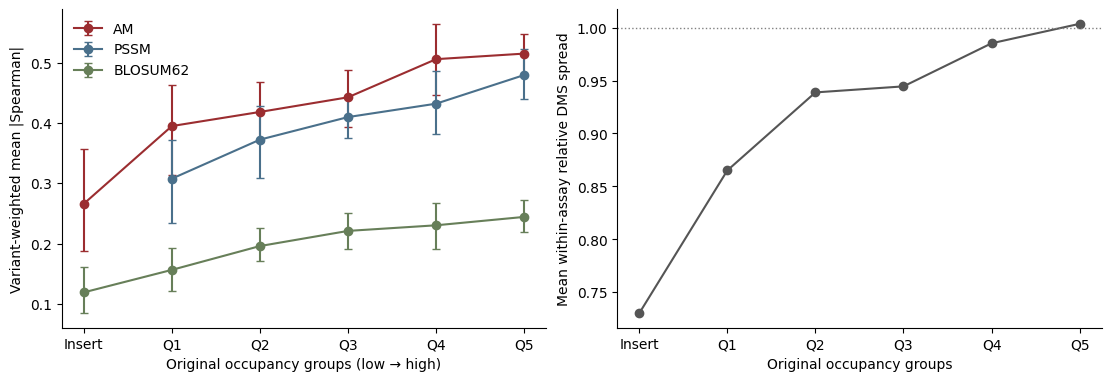

In [20]:
fig,axs=plt.subplots(1,2,figsize=(11,3.7),constrained_layout=True)
order=['insert','q0','q1','q2','q3','q4']
for predictor,color in [('AM','#9b2d30'),('PSSM','#4a708b'),('BLOSUM62','#677f59')]:
    sub=curve[(curve.predictor==predictor)&curve.bin.isin(order)].set_index('bin').reindex(order)
    y=sub.wmean_absrho.to_numpy();lo=sub['ci2.5'].to_numpy();hi=sub['ci97.5'].to_numpy()
    axs[0].errorbar(range(6),y,yerr=[y-lo,hi-y],marker='o',capsize=3,label=predictor,color=color)
axs[0].set_xticks(range(6),['Insert','Q1','Q2','Q3','Q4','Q5']);axs[0].set_xlabel('Original occupancy groups (low → high)');axs[0].set_ylabel('Variant-weighted mean |Spearman|');axs[0].legend(frameon=False)
spread=pd.read_csv(OUT/'axis3_dms_signal_perbin.tsv',sep='\t').set_index('bin').reindex(order)
axs[1].plot(range(6),spread.mean_relative_spread,'o-',color='#555555');axs[1].axhline(1,color='grey',ls=':',lw=1)
axs[1].set_xticks(range(6),['Insert','Q1','Q2','Q3','Q4','Q5']);axs[1].set_ylabel('Mean within-assay relative DMS spread');axs[1].set_xlabel('Original occupancy groups')
for ax in axs:ax.spines[['top','right']].set_visible(False)
fig.savefig(OUT/'occupancy_and_dynamic_range.png',dpi=180);plt.show()


## 5. Controls, depth gate and confirmation boundary

The high-depth subset tests whether low occupancy matters when many homologs are available. The paired sign test compares assays present at both ends; it is not independent external replication. The baseline and DMS-range controls test shared difficulty and response-range changes on the same measurements. All original scientific decisions are retained.

The initial absolute depth groups are audited from the original frozen table. The independently rebuilt alignment features reproduce every depth-bin assignment; their OTU7A numerical discrepancy is documented in the upstream notebook.

In [21]:
from scipy.stats import binomtest
paired=[]
for name,high,low in [('coarse','coarse_easy','coarse_hard'),('occupancy','q4','q0'),('high_depth','deep_occ>=0.9','deep_occ<0.7')]:
    tab=replayed[replayed.bin_label.isin([high,low])].pivot(index='assay',columns='bin_label',values='abs_rho').dropna()
    diff=tab[high]-tab[low];positive=int((diff>0).sum());n=len(diff)
    paired.append(dict(comparison=name,n_pairs=n,n_positive=positive,p_two_sided=binomtest(positive,n,.5).pvalue,mean_difference=diff.mean(),median_difference=diff.median()))
paired=pd.DataFrame(paired);paired.to_csv(OUT/'paired_sign_checks.csv',index=False)
assert int(paired.loc[paired.comparison.eq('occupancy'),'n_positive'].iloc[0])==44
assert int(paired.loc[paired.comparison.eq('high_depth'),'n_positive'].iloc[0])==24
frozen=pd.read_csv(INPUT/'axis3_pathC_percolumn_FROZEN.tsv',sep='\t')
# Reproduce original protein-position gate unit, without counting repeat assays twice.
distinct=frozen.drop_duplicates(['accession','target_pos'])
levels=distinct[distinct.low_cov_insert.eq(0)].groupby('depth_bin').agg(positions=('target_pos','size'),proteins=('accession','nunique'))
levels.to_csv(OUT/'absolute_depth_group_support.csv')
print('Paired within-assay checks (same cohort):');display(paired)
print('Original absolute depth groups:');display(levels)
assert levels.loc[0,'proteins']==1 and levels.loc[1,'proteins']==2
print('No independent confirmation cohort is retained or asserted. The upstream notebook documents the executed alignment reconstruction and isolated OTU7A difference.')


Paired within-assay checks (same cohort):


,comparison,n_pairs,n_positive,p_two_sided,mean_difference,median_difference
0,coarse,61,47,0.000027,0.124115,0.15180
1,occupancy,53,44,0.000001,0.111889,0.08810
2,high_depth,28,24,0.000180,0.202054,0.21615


Original absolute depth groups:


,positions,proteins
depth_bin,,
0.0,6,1
1.0,7,2
2.0,166,8
3.0,1289,16
4.0,11647,52


No independent confirmation cohort is retained or asserted. The upstream notebook documents the executed alignment reconstruction and isolated OTU7A difference.


## Interpretation and reproducibility boundary

The original occupancy curve, high-depth interaction, PSSM/BLOSUM comparisons, dynamic-range control and saved confidence intervals reproduce from individual measurements. They support the same bounded result: agreement is lower at harder-to-align positions, and the reference predictors also decline. These same-dataset controls do not establish an AlphaMissense-specific generalization failure or independent confirmation.

The complete raw alignments and original feature programs are included and were executed. The archived-feature track reproduced here and the independently rebuilt-feature sensitivity are kept separate because OTU7A has a small unresolved weighted-count difference. See the upstream notebook for the exact changed positions, reconstructed baseline scores and downstream comparison. The separate original ClinVar screens have their own executed notebooks and preserved source records.

In [22]:
outputs=[]
for p in sorted(OUT.glob('*')):
    if p.is_file():outputs.append(dict(path=p.name,sha256=hashlib.sha256(p.read_bytes()).hexdigest(),bytes=p.stat().st_size))
(OUT/'OUTPUT_MANIFEST.json').write_text(json.dumps(outputs,indent=2))
print(len(outputs),'executed replay outputs saved and hashed.')


13 executed replay outputs saved and hashed.


## Original agent determination

**Rejected.** The two shallowest groups covered only one or two proteins. Occupancy became the primary axis.

This counts the sequence support for each protein position while reducing the influence of nearly identical sequences. The audit checked whether its planned support groups contained enough different proteins and found that the shallowest groups were too narrowly represented.

This is the historical determination recorded in the investigation index. It is preserved alongside the actual calculations, including negative results and preparation-only decisions.